<a href="https://colab.research.google.com/github/HarshPrajapati7/GridAttention/blob/main/GRIDTWIN24_FINAL_Research_Grade_Forecasting_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GRIDTWIN-24 — Final research-grade day-ahead grid-demand forecasting

**Dataset:** [Hack Day Lucknow · P2 Grid Demand Forecast](https://github.com/CodewithJha/hack-day-lucknow-datasets/tree/main/p2-grid-demand-forecast)

This notebook is built around the actual dataset description, not a generic time-series template. It forecasts the next 24 hourly `demand_mw` values, tests for time/data inconsistencies, compares classical and modern models, evaluates temporal generalisation, calibrates uncertainty, and exports the organiser's forecast schema.

## Dataset facts from the repository README

- `history.csv`: 79,283 hourly records, published range 2015-04-19 00:00 through 2024-06-16 23:00.
- Target: `demand_mw`.
- Other columns include generation, load shedding, fuel mix, renewables and cross-border/import fields.
- The README explicitly warns about missing hours, typo-like spikes (including values around 121,000 MW), and import columns that begin later in the record.
- Required output example: `timestamp,demand_mw,p10,p90`.

The notebook always re-reads the repository CSV in Colab and records its SHA-256 and Git blob hash. If the organisers update or hide records, the notebook reports the change instead of assuming the README's row count is still correct.

## Modelling philosophy

There is no defensible way to guarantee near-perfect accuracy before evaluation. The objective here is **maximum honest out-of-time performance without leakage or silent data manipulation**.

The pipeline compares:

1. Seasonal-naïve daily and weekly baselines.
2. Direct multi-horizon LightGBM and CatBoost using only values available at forecast issue time.
3. GPU-trained DLinear and PatchTST neural challengers.
4. Optional zero-shot Chronos-2 foundation-model forecasts.
5. A validation-only ensemble when it improves out-of-time results.

The final chronological holdout is not used for tuning, model selection or ensemble-weight fitting.

## Critical forecasting contract

**Forecast issue time:** 23:00 on the day before the requested forecast date, matching a day-ahead 00:00–23:00 forecast. The notebook does not infer a timezone because the dataset README does not specify one; timestamps remain in the dataset's published clock.

**Hidden/ISO forecast date:** set `FORECAST_DATE = "YYYY-MM-DD"` in the configuration cell when the organisers provide the date. The notebook truncates all modelling inputs at the preceding 23:00. If the date is omitted, it forecasts the day after the final timestamp in the downloaded history.

**No future operational features:** generation, fuel mix, load-shedding and imports may be outcomes of contemporaneous grid operations. They are only used as historical lags/rolling summaries observed at or before the forecast origin. No future generation, imports, weather or demand is supplied to the model.

**Target quality:** raw observations are never overwritten. Gross typo candidates are separately flagged using a causal seasonal reference. The notebook reports both raw-observation and quality-reviewed metrics. A flagged low or high value is not automatically deleted from the archive; masking is a configurable modelling policy and all excluded timestamps are exported.

**Missingness:** no backward fill, centred rolling statistic, full-series interpolation or future-assisted imputation is allowed. Long missing target gaps remain gaps and are surfaced in the audit.

**Validation:** rolling-origin windows are distributed over the historical timeline, with an additional recent untouched chronological holdout. A later forecast origin may use actual values that would have become observable by that later origin, but no model is trained on labels after the first origin in its validation window.

## 0. Runtime and configuration

Use a Colab **T4 GPU** runtime. LightGBM and CatBoost are tree models (CPU training is normally appropriate); PatchTST/DLinear and Chronos-2 use the GPU when available. The notebook also runs without a GPU, but neural/foundation benchmarks will be slower.

Run top to bottom in a fresh runtime. Do not edit the dataset preprocessing cells merely to improve a score. Change model settings only after the first full benchmark has completed.

In [1]:
%pip -q install -U lightgbm catboost optuna pyarrow chronos-forecasting

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
from __future__ import annotations
import os, sys, json, math, time, hashlib, random, warnings, platform, subprocess, gc, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from catboost import CatBoostRegressor
from scipy.optimize import minimize

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- USER SETTINGS ----------------
DATA_URL = "https://raw.githubusercontent.com/CodewithJha/hack-day-lucknow-datasets/main/p2-grid-demand-forecast/history.csv"
EXPECTED_GIT_BLOB_SHA1 = "bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e"
EXPECTED_ROWS_FROM_README = 79_283

# Enter the organisers' hidden ISO date here, e.g. "2024-06-10".
# None means the day immediately following the final timestamp in history.csv.
FORECAST_DATE = None

HOLDOUT_DAYS = 28
CV_FOLDS = 5
CV_DAYS = 14
MIN_TRAIN_DAYS = 365 * 2

# Conservative, causal gross-error policy. All candidates are exported before masking.
AUTO_MASK_GROSS_TARGET_ERRORS = True
SEASONAL_HISTORY_WEEKS = 104
MIN_SEASONAL_PEERS = 16
EXTREME_HIGH_RATIO = 3.0
EXTREME_LOW_RATIO = 0.15
ROBUST_Z_THRESHOLD = 10.0

# Model training
RUN_OPTUNA = True
OPTUNA_TRIALS = 30
RUN_PATCHTST = True
RUN_DLINEAR = True
RUN_CHRONOS2 = True
PATCHTST_EPOCHS = 60
PATCHTST_PATIENCE = 10
PATCH_LOOKBACK = 672       # 28 days of hourly context
PATCH_LEN = 24
PATCH_STRIDE = 12
PATCH_D_MODEL = 128
PATCH_HEADS = 4
PATCH_LAYERS = 3
PATCH_DROPOUT = 0.15

# CV windows are distributed through history; recent holdout remains separate.
USE_CONTEXT_COVARIATES = True
MAX_CONTEXT_MISSING_FRACTION = 0.10

OUTDIR = Path("/content/GRIDTWIN24_FINAL_OUTPUTS")
OUTDIR.mkdir(parents=True, exist_ok=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    try: torch.set_float32_matmul_precision("high")
    except Exception: pass
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "numpy:", np.__version__, "torch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
print("Forecast date override:", FORECAST_DATE)

Python: 3.13.16
pandas: 2.2.3 numpy: 2.1.3 torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Forecast date override: None


## 1. Download and fingerprint the exact dataset

The GitHub raw file is downloaded directly. The SHA-256 and Git blob SHA are recorded to make the run reproducible. A changed hash is a warning, not an automatic failure: the organisers may add hidden dates or revise the public dataset. The schema is checked separately.

In [3]:
import requests

CSV_PATH = Path("/content/history.csv")
if not CSV_PATH.exists():
    resp = requests.get(DATA_URL, timeout=180)
    resp.raise_for_status()
    if len(resp.content) < 1_000_000:
        raise RuntimeError(f"Downloaded CSV is unexpectedly small ({len(resp.content):,} bytes). Check repository URL/access.")
    CSV_PATH.write_bytes(resp.content)

blob = CSV_PATH.read_bytes()
sha256 = hashlib.sha256(blob).hexdigest()
git_blob_sha1 = hashlib.sha1(b"blob " + str(len(blob)).encode() + b"\x00" + blob).hexdigest()
print(f"Downloaded bytes: {len(blob):,}")
print("SHA-256:", sha256)
print("Git blob SHA-1:", git_blob_sha1)
if git_blob_sha1 != EXPECTED_GIT_BLOB_SHA1:
    warnings.warn("CSV Git blob SHA differs from the inspected repository version. Check whether the organisers updated the dataset.")

raw = pd.read_csv(CSV_PATH, low_memory=False)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
required = {"timestamp", "demand_mw"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing required columns: {required - set(raw.columns)}")
if len(raw) != EXPECTED_ROWS_FROM_README:
    warnings.warn(f"README listed {EXPECTED_ROWS_FROM_README:,} rows; this CSV contains {len(raw):,}. Inspect the audit; do not force the expected row count.")

Downloaded bytes: 5,240,286
SHA-256: 8af13c5a525398d8834cdbd0b034cc56724eb23b55df5ad9df674c327e24b297
Git blob SHA-1: bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e
Shape: (79283, 14)
Columns: ['timestamp', 'generation_mw', 'demand_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']


## 2. Timestamp, duplicate, schema and frequency audit

This stage catches malformed or duplicated timestamps, off-hour records, non-numeric measurements, missing hourly slots and long target gaps. Conflicting duplicate timestamps are not silently averaged: they are exported and the pipeline stops so the resolution can be deliberate.

In [4]:
raw = raw.copy()
raw["timestamp_raw"] = raw["timestamp"].astype(str)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="coerce")

bad_ts = raw["timestamp"].isna()
if bad_ts.any():
    display(raw.loc[bad_ts, ["timestamp_raw"]].head(30))
    raise ValueError(f"Found {int(bad_ts.sum())} unparseable timestamps. Resolve explicitly before modelling.")
if getattr(raw["timestamp"].dt, "tz", None) is not None:
    raise ValueError("Timezone-aware timestamps found. The dataset README does not declare a timezone/DST convention; confirm before converting.")

off_hour = ((raw.timestamp.dt.minute != 0) | (raw.timestamp.dt.second != 0) | (raw.timestamp.dt.microsecond != 0))
if off_hour.any():
    display(raw.loc[off_hour, ["timestamp_raw", "timestamp"]].head(30))
    raise ValueError(f"Found {int(off_hour.sum())} off-hour timestamps. Do not round them silently.")

value_cols = [c for c in raw.columns if c not in ["timestamp", "timestamp_raw"]]
coercion_report = []
for c in value_cols:
    before = raw[c].notna().sum()
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
    coercion_report.append({"column": c, "new_nans_after_numeric_parse": int(before - raw[c].notna().sum())})

# Exact duplicate rows can be safely removed; conflicting duplicate timestamps are escalated.
exact_dup = raw.drop(columns=["timestamp_raw"]).duplicated().sum()
raw = raw.drop_duplicates(subset=["timestamp"] + value_cols, keep="first")
dup_mask = raw.timestamp.duplicated(keep=False)
conflicting_duplicates = raw.loc[dup_mask].sort_values("timestamp").copy()
print("Exact duplicate rows removed:", int(exact_dup))
print("Rows in conflicting duplicate timestamps:", len(conflicting_duplicates))
if len(conflicting_duplicates):
    conflicting_duplicates.to_csv(OUTDIR / "conflicting_duplicate_timestamps.csv", index=False)
    display(conflicting_duplicates.head(30))
    raise ValueError("Conflicting duplicate timestamps detected. Inspect conflicting_duplicate_timestamps.csv and resolve deliberately.")

raw = raw.drop(columns=["timestamp_raw"], errors="ignore").sort_values("timestamp").set_index("timestamp")
if not raw.index.is_monotonic_increasing:
    raise RuntimeError("Timestamp index is not monotonic after sorting.")
if raw.index.has_duplicates:
    raise RuntimeError("Duplicate timestamps remain after de-duplication.")

DATA_LAST_TIMESTAMP = raw.index.max()
full_index = pd.date_range(raw.index.min(), DATA_LAST_TIMESTAMP, freq="h", name="timestamp")
full_hourly = raw.reindex(full_index)

# Resolve the exact day-ahead origin before any target anomaly detection/model selection.
if FORECAST_DATE is None:
    CONFIG_FORECAST_DAY = DATA_LAST_TIMESTAMP.normalize() + pd.Timedelta(days=1)
else:
    CONFIG_FORECAST_DAY = pd.Timestamp(FORECAST_DATE).normalize()
CONFIG_FORECAST_ORIGIN = CONFIG_FORECAST_DAY - pd.Timedelta(hours=1)
if CONFIG_FORECAST_ORIGIN > DATA_LAST_TIMESTAMP:
    raise ValueError(f"Requested forecast origin {CONFIG_FORECAST_ORIGIN} is after dataset end {DATA_LAST_TIMESTAMP}. No valid recent history exists.")
if CONFIG_FORECAST_ORIGIN not in full_hourly.index:
    raise ValueError(f"Requested forecast origin {CONFIG_FORECAST_ORIGIN} is not an exact hourly timestamp in the dataset.")
if CONFIG_FORECAST_ORIGIN < full_hourly.index.min() + pd.Timedelta(days=28):
    raise ValueError("Requested forecast date does not have at least 28 days of history.")

# From this point onward, even anomaly thresholds, CV folds and tuning see no records after origin.
hourly = full_hourly.loc[:CONFIG_FORECAST_ORIGIN].copy()
full_index = hourly.index
missing_hour_index = full_index.difference(raw.loc[:CONFIG_FORECAST_ORIGIN].index)

# Missing intervals are computed only through the issue origin, never using post-origin data.
missing_rows = []
missing_flag = hourly["demand_mw"].isna().to_numpy()
start = None
for i, flag in enumerate(missing_flag):
    if flag and start is None: start = i
    if (not flag or i == len(missing_flag)-1) and start is not None:
        end = i-1 if not flag else i
        missing_rows.append({"start": full_index[start], "end": full_index[end], "hours": end-start+1})
        start = None
missing_intervals = pd.DataFrame(missing_rows)
missing_intervals.to_csv(OUTDIR / "missing_target_intervals.csv", index=False)

print("Original dataset end:", DATA_LAST_TIMESTAMP)
print("Modelling data cutoff:", hourly.index.max())
print("Requested ISO forecast date:", CONFIG_FORECAST_DAY.date())
print("Strict modelling cutoff / issue origin:", CONFIG_FORECAST_ORIGIN)
print("First timestamp in modelling slice:", hourly.index.min())
print("Rows retained through issue origin:", len(hourly))
print("Missing hourly slots through origin:", len(missing_hour_index))
print("Missing demand intervals through origin:", len(missing_intervals))
print("Longest missing demand interval through origin:", int(missing_intervals.hours.max()) if len(missing_intervals) else 0, "hours")
display(pd.DataFrame(coercion_report))

Exact duplicate rows removed: 0
Rows in conflicting duplicate timestamps: 0
Original dataset end: 2024-06-16 23:00:00
Modelling data cutoff: 2024-06-16 23:00:00
Requested ISO forecast date: 2024-06-17
Strict modelling cutoff / issue origin: 2024-06-16 23:00:00
First timestamp in modelling slice: 2015-04-19 00:00:00
Rows retained through issue origin: 80328
Missing hourly slots through origin: 1045
Missing demand intervals through origin: 222
Longest missing demand interval through origin: 517 hours


,column,new_nans_after_numeric_parse
0,generation_mw,0
1,demand_mw,0
2,load_shedding,0
3,gas,0
4,liquid_fuel,0
5,coal,0
6,hydro,0
7,solar,0
8,wind,0
9,india_bheramara_hvdc,0


## 3. Target and covariate forensic audit

The audit includes quantiles, negative/zero checks, per-column coverage, first/last availability, long gaps and timeline plots. The README warns about both impossible-looking spikes and incomplete imports. Missingness is treated as information, not silently filled into the training target.

,demand_mw
count,79283.000000
mean,8461.528739
std,2549.550226
min,6.000000
0.1%,3222.794000
0.5%,3813.000000
1%,4094.640000
5%,4995.000000
50%,8089.000000
95%,13000.000000


,non_missing,missing_pct,first_available,last_available,unique_values
india_adani,0,100.000000,NaT,NaT,0
nepal,0,100.000000,NaT,NaT,0
wind,9146,88.614182,2023-06-01 06:00:00,2024-06-16 23:00:00,66
solar,58766,26.842446,2017-09-20 06:00:00,2024-06-16 23:00:00,847
generation_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,20051
liquid_fuel,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,5552
gas,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,4791
load_shedding,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,1968
demand_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,10178
coal,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00,4515


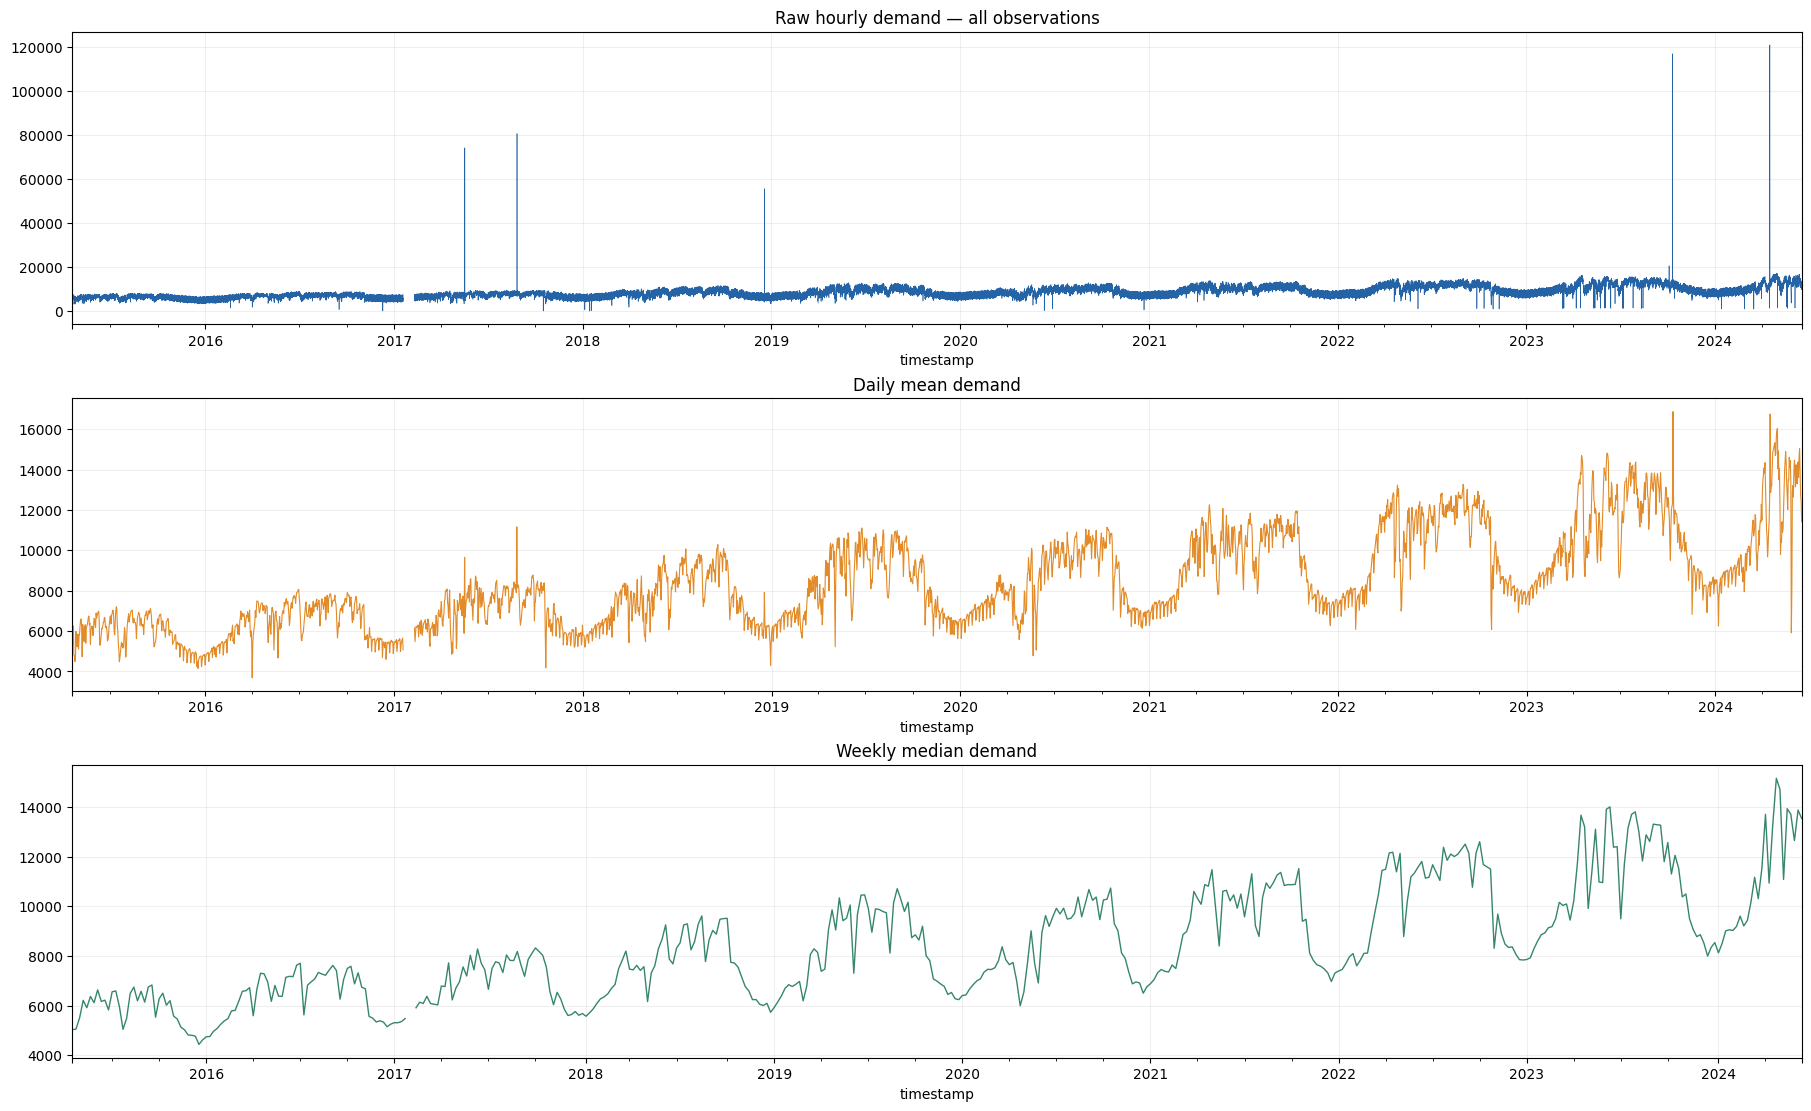

Negative target rows: 0
Zero target rows: 0
Positive target minimum: 6.0


In [5]:
target_raw = hourly["demand_mw"].astype(float).copy()
summary = target_raw.describe(percentiles=[.001,.005,.01,.05,.5,.95,.99,.995,.999]).to_frame("demand_mw")
display(summary)
coverage = pd.DataFrame({
    "non_missing": hourly.notna().sum(),
    "missing_pct": 100 * hourly.isna().mean(),
    "first_available": [hourly[c].first_valid_index() for c in hourly.columns],
    "last_available": [hourly[c].last_valid_index() for c in hourly.columns],
    "unique_values": [hourly[c].nunique(dropna=True) for c in hourly.columns],
}).sort_values("missing_pct", ascending=False)
display(coverage)
coverage.to_csv(OUTDIR / "column_coverage_audit.csv")

fig, ax = plt.subplots(3, 1, figsize=(18, 11), constrained_layout=True)
target_raw.plot(ax=ax[0], lw=.45, color="#2463a6", title="Raw hourly demand — all observations")
target_raw.resample("D").mean().plot(ax=ax[1], lw=.8, color="#e28b28", title="Daily mean demand")
target_raw.resample("W").median().plot(ax=ax[2], lw=1.0, color="#36866b", title="Weekly median demand")
for a in ax: a.grid(alpha=.2)
plt.show()

print("Negative target rows:", int((target_raw < 0).sum()))
print("Zero target rows:", int((target_raw == 0).sum()))
print("Positive target minimum:", float(target_raw[target_raw > 0].min()))

## 4. Causal anomaly audit: high spikes, low collapses and possible regime shifts

The README explicitly identifies typo-like high spikes. The previous run also showed suspicious low observations and abrupt drops. This version uses a **symmetric** upper/lower seasonal outlier test based on the preceding 104 observations for the same hour-of-week. It flags candidates but does not erase them from the raw series.

A candidate is classed as a gross target error only when the robust seasonal deviation and relative deviation both exceed conservative thresholds. Possible sustained level shifts are reported separately and are never auto-masked. Review the exported audit before changing the thresholds.

High-spike candidates: 5
Low-collapse candidates: 0
Nonpositive candidates: 0
Gross candidates masked for modelling: 5
Possible regime-shift hours (not masked): 3519


,demand_raw_mw,past_hour_of_week_median,past_robust_scale,robust_z,ratio_to_seasonal_median,high_spike_candidate,low_collapse_candidate,nonpositive_candidate,gross_candidate,possible_regime_shift,masked_for_model
timestamp,,,,,,,,,,,
2017-05-17 12:00:00,74223.0,6444.5,927.538918,73.073484,11.517263,True,False,False,True,False,True
2024-04-16 07:00:00,121000.0,9698.5,1639.547813,67.885486,12.476156,True,False,False,True,False,True
2017-08-26 15:00:00,80689.0,6372.5,1438.843588,51.650159,12.662064,True,False,False,True,False,True
2018-12-18 08:00:00,55639.0,6718.5,1146.960712,42.652289,8.281462,True,False,False,True,False,True
2023-10-11 03:00:00,117000.0,10264.0,3727.575982,28.634158,11.399065,True,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...
2019-04-30 15:00:00,10488.0,7203.0,1361.378799,2.412995,1.456060,False,False,False,False,True,False
2024-04-29 11:00:00,15800.0,11101.5,1948.295033,2.411596,1.423231,False,False,False,False,True,False
2019-04-30 16:00:00,10087.0,7193.0,1200.518903,2.410624,1.402336,False,False,False,False,True,False


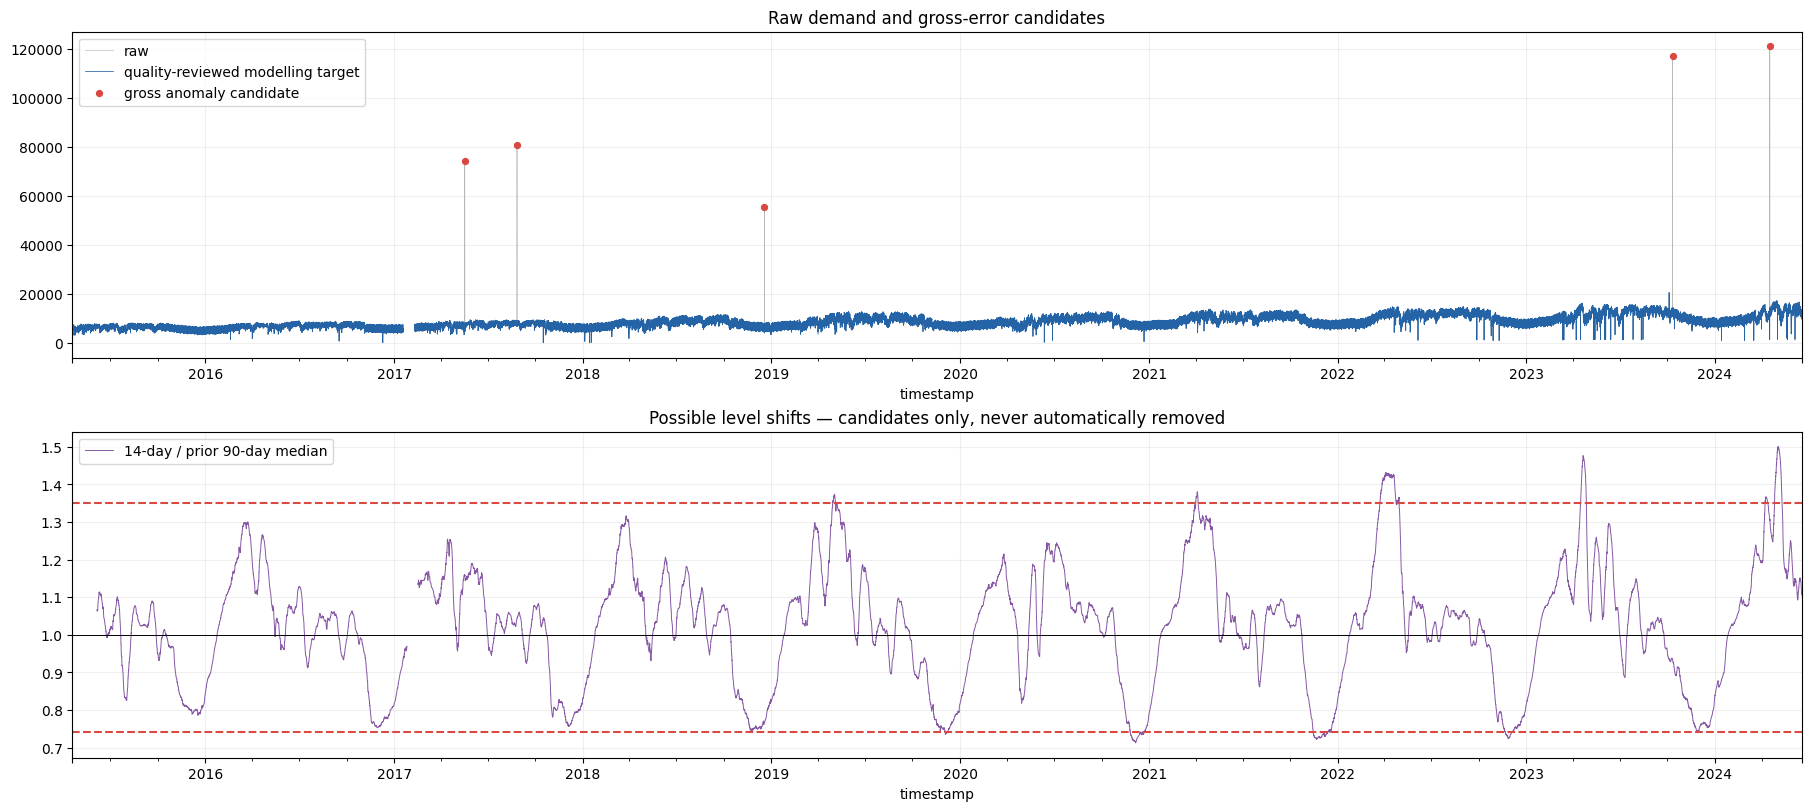

In [6]:
slot = pd.Series(hourly.index.dayofweek * 24 + hourly.index.hour, index=hourly.index)

def _rolling_by_slot(series: pd.Series, statistic: str, window: int, min_periods: int):
    out = pd.Series(index=series.index, dtype=float)
    for _, idx in series.groupby(slot).groups.items():
        g = series.loc[idx]
        past = g.shift(1)
        if statistic == "median": v = past.rolling(window, min_periods=min_periods).median()
        elif statistic == "q25": v = past.rolling(window, min_periods=min_periods).quantile(.25)
        elif statistic == "q75": v = past.rolling(window, min_periods=min_periods).quantile(.75)
        else: raise ValueError(statistic)
        out.loc[idx] = v.values
    return out.sort_index()

seasonal_median = _rolling_by_slot(target_raw, "median", SEASONAL_HISTORY_WEEKS, MIN_SEASONAL_PEERS)
seasonal_q25 = _rolling_by_slot(target_raw, "q25", SEASONAL_HISTORY_WEEKS, MIN_SEASONAL_PEERS)
seasonal_q75 = _rolling_by_slot(target_raw, "q75", SEASONAL_HISTORY_WEEKS, MIN_SEASONAL_PEERS)
seasonal_scale = ((seasonal_q75 - seasonal_q25) / 1.349).clip(lower=1.0)

# Expanding past-only fallback for the very beginning of the record.
past_global_median = target_raw.expanding(min_periods=24*14).median().shift(1)
seasonal_median = seasonal_median.fillna(past_global_median)
seasonal_scale = seasonal_scale.fillna((target_raw - past_global_median).abs().expanding(min_periods=24*14).median().shift(1) * 1.4826)
seasonal_scale = seasonal_scale.clip(lower=1.0)
robust_z = (target_raw - seasonal_median) / seasonal_scale
ratio = target_raw / seasonal_median.replace(0, np.nan)

high_candidate = target_raw.notna() & seasonal_median.notna() & (ratio >= EXTREME_HIGH_RATIO) & (robust_z >= ROBUST_Z_THRESHOLD)
low_candidate = target_raw.notna() & seasonal_median.notna() & (ratio <= EXTREME_LOW_RATIO) & (robust_z <= -ROBUST_Z_THRESHOLD)
nonpositive = target_raw.notna() & (target_raw <= 0)
gross_candidate = high_candidate | low_candidate | nonpositive

# Potential structural regime shifts: 14-day rolling median compared to a prior 90-day median.
recent_med = target_raw.rolling(24*14, min_periods=24*7).median()
prior_med = target_raw.shift(24*14).rolling(24*90, min_periods=24*30).median()
regime_ratio = recent_med / prior_med.replace(0, np.nan)
regime_shift_candidate = regime_ratio.notna() & ((regime_ratio > 1.35) | (regime_ratio < 0.74))

anomaly_audit = pd.DataFrame({
    "demand_raw_mw": target_raw,
    "past_hour_of_week_median": seasonal_median,
    "past_robust_scale": seasonal_scale,
    "robust_z": robust_z,
    "ratio_to_seasonal_median": ratio,
    "high_spike_candidate": high_candidate,
    "low_collapse_candidate": low_candidate,
    "nonpositive_candidate": nonpositive,
    "gross_candidate": gross_candidate,
    "possible_regime_shift": regime_shift_candidate,
})

# Optional manual override: timestamps to mask only after independent review.
MANUAL_BAD_TIMESTAMPS = []
manual_mask = pd.Series(False, index=hourly.index)
if MANUAL_BAD_TIMESTAMPS:
    manual_mask.loc[pd.to_datetime(MANUAL_BAD_TIMESTAMPS)] = True

mask_target = (gross_candidate if AUTO_MASK_GROSS_TARGET_ERRORS else pd.Series(False, index=hourly.index)) | manual_mask
anomaly_audit["masked_for_model"] = mask_target
anomaly_audit.to_csv(OUTDIR / "data_anomaly_audit.csv")
print("High-spike candidates:", int(high_candidate.sum()))
print("Low-collapse candidates:", int(low_candidate.sum()))
print("Nonpositive candidates:", int(nonpositive.sum()))
print("Gross candidates masked for modelling:", int(mask_target.sum()))
print("Possible regime-shift hours (not masked):", int(regime_shift_candidate.sum()))
display(anomaly_audit.loc[gross_candidate | regime_shift_candidate].sort_values("robust_z", key=lambda x: x.abs(), ascending=False).head(100))

# Preserve raw values and create a modelling target.
target_model = target_raw.copy()
target_model.loc[mask_target] = np.nan

fig, ax = plt.subplots(2, 1, figsize=(18, 8), constrained_layout=True)
target_raw.plot(ax=ax[0], lw=.45, color="0.72", label="raw")
target_model.plot(ax=ax[0], lw=.55, color="#2463a6", label="quality-reviewed modelling target")
ax[0].scatter(hourly.index[gross_candidate], target_raw[gross_candidate], s=18, color="#d94841", label="gross anomaly candidate", zorder=5)
ax[0].set_title("Raw demand and gross-error candidates"); ax[0].legend(); ax[0].grid(alpha=.2)
regime_ratio.plot(ax=ax[1], lw=.7, color="#8759a5", label="14-day / prior 90-day median")
ax[1].axhline(1, color="black", lw=.7); ax[1].axhline(1.35, color="#d94841", ls="--"); ax[1].axhline(.74, color="#d94841", ls="--")
ax[1].set_title("Possible level shifts — candidates only, never automatically removed"); ax[1].legend(); ax[1].grid(alpha=.2)
plt.show()

## 5. Past-only target preparation and operational-covariate policy

The modelling target keeps true gaps and gross-error candidates as missing labels. For input context only, short forward-fill is allowed, followed by the same hour one week earlier, then a shifted expanding median. No backward fill or future interpolation is used. Missingness flags remain available to the models.

Operational columns are only historical inputs. A covariate that is 100% missing is excluded. Sparse covariates can remain in the context challenger with missingness/age indicators, but a demand-only model is always retained as a clean benchmark.

In [7]:
# Past-only target input series for lags/windows. This is NOT the target label series.
y_input = target_model.ffill(limit=3)
y_input = y_input.fillna(target_model.shift(168))
y_input = y_input.fillna(target_model.expanding(min_periods=24*14).median().shift(1))

# Remaining early/long-gap NaNs stay missing; no bfill.
y_missing_flag = target_model.isna().astype(float)

# Historical operational covariates: remove fully absent columns and timestamp/export artefacts.
OPERATIONAL_CANDIDATES = [c for c in [
    "generation_mw", "load_shedding", "gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
    "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal"
] if c in hourly.columns and hourly[c].notna().any()]
print("Operational covariates available:", OPERATIONAL_CANDIDATES)

covariate_coverage = hourly[OPERATIONAL_CANDIDATES].notna().mean().sort_values(ascending=False).rename("coverage_fraction").to_frame() if OPERATIONAL_CANDIDATES else pd.DataFrame()
display(covariate_coverage)

# Create arrays for fast, explicit point-in-time feature construction.
idx = hourly.index
N = len(idx)
y_raw_arr = target_raw.to_numpy(dtype=float)
y_model_arr = target_model.to_numpy(dtype=float)
y_input_arr = y_input.to_numpy(dtype=float)
y_missing_arr = y_missing_flag.to_numpy(dtype=float)

cov_arrays = {c: hourly[c].to_numpy(dtype=float) for c in OPERATIONAL_CANDIDATES}

# If the same timestamp is ever observed under multiple timezone interpretations, do not proceed silently.
if not isinstance(idx, pd.DatetimeIndex) or not idx.is_monotonic_increasing or idx.has_duplicates:
    raise RuntimeError("Invalid timestamp index after audit.")

print("Usable target labels:", int(np.isfinite(y_model_arr).sum()))
print("Target values excluded from modelling:", int(mask_target.sum()))
print("Missing/flagged target percentage:", round(100*np.mean(~np.isfinite(y_model_arr)), 3))

Operational covariates available: ['generation_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura']


,coverage_fraction
generation_mw,0.986991
load_shedding,0.986991
gas,0.986991
liquid_fuel,0.986991
coal,0.986991
hydro,0.986991
india_tripura,0.986991
india_bheramara_hvdc,0.986991
solar,0.731576
wind,0.113858


Usable target labels: 79278
Target values excluded from modelling: 5
Missing/flagged target percentage: 1.307


## 6. Leakage-safe feature engineering for a direct 24-horizon model

Each training row is one `(forecast_origin, horizon)` pair. All target lags are aligned to the target timestamp but use lags of at least 24 hours, so even horizon 24 never reads beyond the 23:00 origin. Additional recent-history summaries end exactly at the origin. Future calendar facts are allowed because they are known at issue time.

Two feature views are evaluated:

- **Demand-only:** demand history, calendar and horizon features.
- **Context:** demand-only plus historical generation/fuel/import summaries measured no later than the origin.

In [8]:
ORIGIN_LAGS = [0,1,2,3,6,12,24,48,72,168,336,504,672]
TARGET_ALIGNED_LAGS = [24,48,72,168,336,504,672]
ROLL_WINDOWS = [6,24,72,168,336,672]


def _safe_value(arr, pos):
    if pos < 0 or pos >= len(arr): return np.nan
    v = arr[pos]
    return float(v) if np.isfinite(v) else np.nan


def calendar_features(ts: pd.Timestamp, horizon: int) -> dict:
    hour = ts.hour
    dow = ts.dayofweek
    doy = ts.dayofyear
    week = int(ts.isocalendar().week)
    return {
        "horizon": int(horizon),
        "hour": hour, "dow": dow, "day_of_year": doy, "month": ts.month,
        "week_of_year": week, "is_weekend": int(dow >= 5),
        "hour_sin": np.sin(2*np.pi*hour/24), "hour_cos": np.cos(2*np.pi*hour/24),
        "dow_sin": np.sin(2*np.pi*dow/7), "dow_cos": np.cos(2*np.pi*dow/7),
        "doy_sin": np.sin(2*np.pi*doy/365.25), "doy_cos": np.cos(2*np.pi*doy/365.25),
        "month_sin": np.sin(2*np.pi*(ts.month-1)/12), "month_cos": np.cos(2*np.pi*(ts.month-1)/12),
        "hour_dow_interaction": hour + 24*dow,
    }


def build_origin_feature_rows(origin_pos: int, include_labels: bool=True) -> list[dict]:
    origin_ts = idx[origin_pos]
    if origin_ts.hour != 23:
        raise ValueError(f"Origin {origin_ts} is not 23:00; expected day-ahead issue convention.")

    common = {
        "origin_hour": origin_ts.hour,
        "origin_dow": origin_ts.dayofweek,
        "origin_month": origin_ts.month,
        "origin_year": origin_ts.year,
        "origin_demand_missing_age_hours": float(np.argmax(np.isfinite(y_model_arr[max(0,origin_pos-24*60):origin_pos+1])[::-1]) if np.isfinite(y_model_arr[max(0,origin_pos-24*60):origin_pos+1]).any() else 24*60+1),
    }
    # Recent context at origin: exact lags, trailing summaries and data-quality rates.
    for lag in ORIGIN_LAGS:
        common[f"origin_demand_lag_{lag}"] = _safe_value(y_input_arr, origin_pos-lag)
        common[f"origin_demand_lag_{lag}_missing"] = float(not np.isfinite(_safe_value(y_model_arr, origin_pos-lag)))

    for w in ROLL_WINDOWS:
        a = max(0, origin_pos-w+1)
        raw_window = y_model_arr[a:origin_pos+1]
        inp_window = y_input_arr[a:origin_pos+1]
        finite_raw = raw_window[np.isfinite(raw_window)]
        finite_inp = inp_window[np.isfinite(inp_window)]
        common[f"origin_demand_roll_mean_{w}"] = float(np.mean(finite_inp)) if len(finite_inp) else np.nan
        common[f"origin_demand_roll_std_{w}"] = float(np.std(finite_inp)) if len(finite_inp)>1 else np.nan
        common[f"origin_demand_roll_median_{w}"] = float(np.median(finite_inp)) if len(finite_inp) else np.nan
        common[f"origin_demand_roll_min_{w}"] = float(np.min(finite_inp)) if len(finite_inp) else np.nan
        common[f"origin_demand_roll_max_{w}"] = float(np.max(finite_inp)) if len(finite_inp) else np.nan
        common[f"origin_demand_raw_coverage_{w}"] = float(np.isfinite(raw_window).mean()) if len(raw_window) else 0.0

    # Operational measurements are summarized strictly at/before origin.
    context = {}
    for col, arr in cov_arrays.items():
        v0 = _safe_value(arr, origin_pos)
        context[f"ctx_{col}_at_origin"] = v0
        for lag in [24,168,672]:
            context[f"ctx_{col}_lag_{lag}"] = _safe_value(arr, origin_pos-lag)
        for w in [24,168,672]:
            a = max(0, origin_pos-w+1)
            ww = arr[a:origin_pos+1]
            good = ww[np.isfinite(ww)]
            context[f"ctx_{col}_mean_{w}"] = float(np.mean(good)) if len(good) else np.nan
            context[f"ctx_{col}_std_{w}"] = float(np.std(good)) if len(good)>1 else np.nan
            context[f"ctx_{col}_coverage_{w}"] = float(np.isfinite(ww).mean()) if len(ww) else 0.0
        valid_before = np.flatnonzero(np.isfinite(arr[:origin_pos+1]))
        context[f"ctx_{col}_age_hours"] = float(origin_pos-valid_before[-1]) if len(valid_before) else float(24*365*20)

    rows=[]
    for h in range(1,25):
        target_pos = origin_pos + h
        # In inference mode, allow future target timestamps beyond the end of history.
        # In supervised sample-building mode, labels must exist in the observed dataset.
        if include_labels and target_pos >= N: continue
        target_ts = origin_ts + pd.Timedelta(hours=h)
        row = {**common, **context, **calendar_features(target_ts, h)}
        for lag in TARGET_ALIGNED_LAGS:
            lag_pos = origin_pos + h - lag
            # This is a hard leakage guard; for h in 1..24 and lag >=24, lag_pos <= origin_pos.
            if lag_pos > origin_pos:
                raise AssertionError("Target-aligned lag illegally accesses the future.")
            row[f"target_aligned_lag_{lag}"] = _safe_value(y_input_arr, lag_pos)
            row[f"target_aligned_lag_{lag}_missing"] = float(not np.isfinite(_safe_value(y_model_arr, lag_pos)))
        row["origin_ts"] = origin_ts
        row["target_ts"] = target_ts
        row["horizon"] = h
        if include_labels:
            row["y_raw"] = y_raw_arr[target_pos]
            row["y"] = y_model_arr[target_pos]
            row["label_masked"] = bool(mask_target.iloc[target_pos])
            row["label_observed"] = bool(np.isfinite(y_raw_arr[target_pos]))
        else:
            row["y_raw"] = np.nan
            row["y"] = np.nan
            row["label_masked"] = False
            row["label_observed"] = False
        rows.append(row)
    return rows

# Day-ahead origins are the 23:00 rows. Exclude the earliest history until 28 days of context exist.
all_origin_pos = [i for i, ts in enumerate(idx) if ts.hour == 23 and i >= 24*28]
feature_rows=[]
for k, pos in enumerate(all_origin_pos):
    feature_rows.extend(build_origin_feature_rows(pos))
    if (k+1) % 500 == 0: print(f"Built {k+1:,}/{len(all_origin_pos):,} daily origins")
samples = pd.DataFrame(feature_rows)
print("Supervised frame:", samples.shape)
print("Unique daily origins:", samples.origin_ts.nunique())
print("Observed raw target rows:", int(samples.label_observed.sum()))
print("Quality-reviewed target rows:", int(samples.y.notna().sum()))

META_COLS = {"origin_ts","target_ts","horizon","y","y_raw","label_masked","label_observed"}
CAL_LAG_COLS = [c for c in samples.columns if c not in META_COLS and not c.startswith("ctx_")]
CTX_COLS = [c for c in samples.columns if c.startswith("ctx_")]
DEMAND_FEATURES = CAL_LAG_COLS
CONTEXT_FEATURES = CAL_LAG_COLS + CTX_COLS

# Drop columns that are entirely missing or constant in the training dataset, but make selection inside each fold too.
print("Demand/calendar features:", len(DEMAND_FEATURES), "Context features:", len(CONTEXT_FEATURES))

Built 500/3,319 daily origins
Built 1,000/3,319 daily origins
Built 1,500/3,319 daily origins
Built 2,000/3,319 daily origins
Built 2,500/3,319 daily origins
Built 3,000/3,319 daily origins
Supervised frame: (79632, 243)
Unique daily origins: 3318
Observed raw target rows: 78674
Quality-reviewed target rows: 78669
Demand/calendar features: 96 Context features: 236


## 7. Automated leakage and timestamp tests

These checks are intentionally strict. They verify that all direct-model historical features are available no later than the issue origin, each target horizon is in 1..24, and changing all raw data strictly after a forecast origin does not alter that origin's generated features.

In [9]:
# Test a representative origin.
test_pos = all_origin_pos[-100]
test_origin = idx[test_pos]
base_rows = build_origin_feature_rows(test_pos, include_labels=False)
assert len(base_rows) == 24
assert all(pd.Timestamp(r["target_ts"]) > test_origin for r in base_rows)
assert all(1 <= int(r["horizon"]) <= 24 for r in base_rows)

# Hard invariant for target-aligned lags.
for r in base_rows:
    ts = pd.Timestamp(r["target_ts"])
    for lag in TARGET_ALIGNED_LAGS:
        assert ts - pd.Timedelta(hours=lag) <= test_origin

# Future perturbation test: rebuild using a copied set of arrays with all post-origin target/covariate values perturbed.
_saved_y_raw, _saved_y_mod, _saved_y_input, _saved_y_miss, _saved_cov = y_raw_arr.copy(), y_model_arr.copy(), y_input_arr.copy(), y_missing_arr.copy(), {k:v.copy() for k,v in cov_arrays.items()}
_future_start = test_pos+1
y_raw_arr[_future_start:] = y_raw_arr[_future_start:] * 17 + 12345
y_model_arr[_future_start:] = y_model_arr[_future_start:] * 17 + 12345
y_input_arr[_future_start:] = y_input_arr[_future_start:] * 17 + 12345
for k in cov_arrays: cov_arrays[k][_future_start:] = cov_arrays[k][_future_start:] * 17 + 9876
perturbed_rows = build_origin_feature_rows(test_pos, include_labels=False)
feature_keys = [k for k in base_rows[0] if k not in ["origin_ts","target_ts","y_raw","y","label_masked","label_observed"]]
for a,b in zip(base_rows, perturbed_rows):
    for k in feature_keys:
        av, bv = a[k], b[k]
        if pd.isna(av) and pd.isna(bv): continue
        if isinstance(av, (int,float,np.number)) and isinstance(bv,(int,float,np.number)):
            assert np.isclose(av,bv,equal_nan=True), f"Future leakage detected in {k}"
        else:
            assert av == bv, f"Future leakage detected in {k}"

y_raw_arr, y_model_arr, y_input_arr, y_missing_arr = _saved_y_raw, _saved_y_mod, _saved_y_input, _saved_y_miss
cov_arrays = _saved_cov
print("PASS: all target lags are available at the issue origin.")
print("PASS: future perturbation does not change forecast-origin features.")
print("PASS: all supervised target timestamps are strictly after their origin.")

PASS: all target lags are available at the issue origin.
PASS: future perturbation does not change forecast-origin features.
PASS: all supervised target timestamps are strictly after their origin.


## 8. Build historical windows for GPU neural models

PatchTST is used as a modern patch-based Transformer challenger; DLinear is a simple but strong neural baseline. These models use 28 days of past demand and predict the following 24 hours. Window inputs contain the demand value plus an explicit missing/suspect indicator. Target labels must be observed and quality-reviewed for all 24 horizons.

The neural models are trained only on windows whose entire 24-hour target is already known at the training cutoff. A chronological validation tail inside the training data controls early stopping. The outer CV and final holdout remain untouched.

In [10]:
LOOKBACK = PATCH_LOOKBACK

def make_input_window_for_origin(origin_pos: int):
    a = origin_pos-LOOKBACK+1
    b = origin_pos+1
    if a < 0: return None
    x_val = y_input_arr[a:b].astype(np.float32)
    x_miss = y_missing_arr[a:b].astype(np.float32)
    if len(x_val) != LOOKBACK or not np.isfinite(x_val).all(): return None
    if float(np.mean(x_miss)) > MAX_CONTEXT_MISSING_FRACTION: return None
    return np.stack([x_val, x_miss], axis=-1)

# Input windows do not depend on future labels. This lets a model forecast even if
# one or more future observed labels are missing/suspect (those rows are simply not scored).
window_cache = {}
for pos in all_origin_pos:
    w = make_input_window_for_origin(pos)
    if w is not None: window_cache[idx[pos]] = w
print("Valid neural input windows:", len(window_cache), "of", len(all_origin_pos))

Valid neural input windows: 3273 of 3319


## 9. Chronological validation design

The recent final holdout is reserved first. The rolling-validation windows are then distributed across the earlier history rather than being concentrated only at the end. Each validation window uses one model fit at the start of that window and advances the forecast origin daily using only actual observations that would have become available by that later origin.

In [11]:
# Eligible origins have at least one valid target row; use the complete list for validation, then score observed rows only.
origin_frame = samples.groupby("origin_ts").agg(
    observed_targets=("label_observed","sum"),
    usable_targets=("y",lambda s: int(s.notna().sum())),
).sort_index()
eligible_origins = list(origin_frame.index)

if len(eligible_origins) < MIN_TRAIN_DAYS + HOLDOUT_DAYS + CV_FOLDS*CV_DAYS:
    raise ValueError(f"Insufficient daily origins ({len(eligible_origins)}) for configured history/holdout/CV settings.")

holdout_origins = eligible_origins[-HOLDOUT_DAYS:]
holdout_start = holdout_origins[0]
pre_holdout = eligible_origins[:-HOLDOUT_DAYS]

# Five well-separated 14-day validation windows, each with >=2 years of prior history.
first_idx = MIN_TRAIN_DAYS
last_idx = len(pre_holdout)-CV_DAYS-1
if last_idx <= first_idx:
    raise ValueError("Not enough pre-holdout history for distributed CV windows.")
starts = np.linspace(first_idx, last_idx, CV_FOLDS).round().astype(int)
folds=[]
used_val_origins=set()
for k, st in enumerate(starts):
    val = pre_holdout[st:st+CV_DAYS]
    if len(val) < CV_DAYS: continue
    if any(x in used_val_origins for x in val): continue
    folds.append({"name":f"fold_{len(folds)+1}","val_origins":val,"val_start":val[0]})
    used_val_origins.update(val)
if len(folds) < 3:
    raise ValueError("Could not construct at least three non-overlapping distributed validation windows.")

print("Final holdout:", holdout_origins[0], "to", holdout_origins[-1])
for f in folds: print(f["name"], f["val_origins"][0], "to", f["val_origins"][-1], "n=", len(f["val_origins"]))

Final holdout: 2024-05-19 23:00:00 to 2024-06-15 23:00:00
fold_1 2017-05-16 23:00:00 to 2017-05-29 23:00:00 n= 14
fold_2 2019-02-11 23:00:00 to 2019-02-24 23:00:00 n= 14
fold_3 2020-11-08 23:00:00 to 2020-11-21 23:00:00 n= 14
fold_4 2022-08-07 23:00:00 to 2022-08-20 23:00:00 n= 14
fold_5 2024-05-04 23:00:00 to 2024-05-17 23:00:00 n= 14


## 10. Baselines and scoring metrics

WAPE is the primary scale-aware error metric for nonnegative demand. MAE, RMSE, sMAPE, mean bias and peak-demand errors are reported alongside it. Metrics are calculated both on quality-reviewed targets and on all raw observed targets; the two must not be conflated.

In [12]:
def metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float); yp = np.asarray(y_pred, dtype=float)
    m = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[m], yp[m]
    if not len(yt): return {"n":0,"MAE":np.nan,"RMSE":np.nan,"WAPE_pct":np.nan,"sMAPE_pct":np.nan,"Bias_MW":np.nan}
    e = yp-yt
    den = np.sum(np.abs(yt))
    smden = np.maximum(np.abs(yt)+np.abs(yp), 1e-9)
    return {"n":int(len(yt)),"MAE":float(np.mean(np.abs(e))),"RMSE":float(np.sqrt(np.mean(e**2))),
            "WAPE_pct":float(100*np.sum(np.abs(e))/den) if den else np.nan,
            "sMAPE_pct":float(100*np.mean(2*np.abs(e)/smden)),"Bias_MW":float(np.mean(e))}

def add_baselines(frame):
    z=frame.copy()
    day=z["target_aligned_lag_24"].astype(float)
    week=z["target_aligned_lag_168"].astype(float)
    fallback=z["origin_demand_roll_mean_24"].astype(float)
    fallback=fallback.fillna(z["origin_demand_roll_mean_168"])
    fallback=fallback.fillna(z["origin_demand_roll_mean_672"])
    day_filled=day.where(np.isfinite(day),week)
    day_filled=day_filled.where(np.isfinite(day_filled),fallback)
    week_filled=week.where(np.isfinite(week),day)
    week_filled=week_filled.where(np.isfinite(week_filled),fallback)
    z["pred_seasonal_day"] = day_filled
    z["pred_seasonal_week"] = week_filled
    z["pred_day_week_mean"] = 0.5*z["pred_seasonal_day"]+0.5*z["pred_seasonal_week"]
    return z

baseline_df=add_baselines(samples)
for c in ["pred_seasonal_day","pred_seasonal_week","pred_day_week_mean"]:
    m=metrics(baseline_df.y,baseline_df[c]); print(c,m)

pred_seasonal_day {'n': 78669, 'MAE': 539.1787108009509, 'RMSE': 881.399430295873, 'WAPE_pct': 6.3596463687785345, 'sMAPE_pct': 6.739685797827644, 'Bias_MW': -1.0972555898765715}
pred_seasonal_week {'n': 78669, 'MAE': 791.5471405509159, 'RMSE': 1243.5607791878947, 'WAPE_pct': 9.336347665959787, 'sMAPE_pct': 9.405022542684629, 'Bias_MW': -13.317291436270958}
pred_day_week_mean {'n': 78669, 'MAE': 552.8712580559052, 'RMSE': 868.2075991466007, 'WAPE_pct': 6.521150813751782, 'sMAPE_pct': 6.661837447548812, 'Bias_MW': -7.207273513073765}


## 11. Tree model definitions

These are direct pooled 24-horizon regressors. `horizon` and target-hour calendar features let one model learn horizon-specific behaviour. LightGBM is the primary candidate; CatBoost is an independent boosted-tree challenger. The demand-only view is the safest benchmark. The context view adds only historical operational information and is kept only if validation justifies it.

In [13]:
BASE_LGB = dict(
    objective="regression_l1", n_estimators=1400, learning_rate=0.025,
    num_leaves=31, max_depth=-1, min_child_samples=50,
    subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
    reg_alpha=0.5, reg_lambda=8.0, random_state=SEED,
    n_jobs=max(1,min(8,os.cpu_count() or 2)), verbosity=-1
)
BASE_CAT = dict(
    iterations=1100, depth=7, learning_rate=0.03, loss_function="MAE",
    eval_metric="MAE", l2_leaf_reg=8.0, random_seed=SEED,
    verbose=False, allow_writing_files=False,
    thread_count=max(1,min(8,os.cpu_count() or 2))
)

META = {"origin_ts","target_ts","horizon","y","y_raw","label_masked","label_observed"}
DEMAND_FEATURES = [c for c in samples.columns if c not in META and not c.startswith("ctx_")]
CONTEXT_FEATURES = DEMAND_FEATURES + [c for c in samples.columns if c.startswith("ctx_")]

# Avoid columns that are all missing/constant in each fold; numeric NaNs are handled by LightGBM/CatBoost.
def usable_features(df, features):
    out=[]
    for c in features:
        s=df[c]
        if s.notna().any() and s.nunique(dropna=True)>1: out.append(c)
    return out

def fit_tree(algo, train_df, feature_kind="demand", params=None):
    feats = DEMAND_FEATURES if feature_kind=="demand" else CONTEXT_FEATURES
    train_df=train_df.loc[train_df.y.notna()].copy()
    feats=usable_features(train_df,feats)
    if not len(train_df) or not feats: raise ValueError("No valid rows/features for tree model.")
    X=train_df[feats].replace([np.inf,-np.inf],np.nan)
    y=train_df.y.astype(float)
    if algo=="lgbm":
        p=BASE_LGB.copy(); p.update(params or {})
        model=LGBMRegressor(**p)
    elif algo=="cat":
        p=BASE_CAT.copy(); p.update(params or {})
        # CatBoost CPU is robust across Colab runtimes; PatchTST/Chronos use T4.
        model=CatBoostRegressor(**p)
    else: raise ValueError(algo)
    model.fit(X,y)
    return model,feats

def predict_tree(model, feats, frame):
    X=frame[feats].replace([np.inf,-np.inf],np.nan)
    return np.maximum(np.asarray(model.predict(X),dtype=float),0.0)

## 12. GPU neural challengers: DLinear and PatchTST

PatchTST segments a history window into patches and encodes them with a Transformer. It is a serious neural challenger, not assumed to outperform boosted trees. DLinear is included as a simpler decomposition-based neural baseline. Both use per-window normalisation and missingness as an explicit input channel.

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

class PatchTST24(nn.Module):
    def __init__(self, lookback=672, horizon=24, patch_len=24, stride=12, d_model=128, n_heads=4, n_layers=3, dropout=0.15):
        super().__init__()
        self.lookback=lookback; self.horizon=horizon; self.patch_len=patch_len; self.stride=stride
        n_patches=(lookback-patch_len)//stride+1
        self.n_patches=n_patches
        self.patch_proj=nn.Linear(patch_len*2,d_model)
        self.pos=nn.Parameter(torch.zeros(1,n_patches,d_model))
        enc=nn.TransformerEncoderLayer(d_model=d_model,nhead=n_heads,dim_feedforward=d_model*4,dropout=dropout,batch_first=True,activation="gelu",norm_first=True)
        self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(n_patches*d_model,256),nn.GELU(),nn.Dropout(dropout),nn.Linear(256,horizon))
        nn.init.trunc_normal_(self.pos,std=0.02)
    def forward(self,x):
        # x: [B,L,2], channel 0 is past-only imputed demand, channel 1 is missing/suspect flag.
        val=x[:,:,0]; miss=x[:,:,1].clamp(0,1)
        w=(1.0-miss)
        mu=(val*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1.0)
        var=(((val-mu)**2)*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1.0)
        sd=torch.sqrt(var.clamp_min(1e-4)).clamp_min(1.0)
        norm=(val-mu)/sd
        z=torch.stack([norm,miss],dim=-1)
        patches=z.unfold(dimension=1,size=self.patch_len,step=self.stride)  # B x patches x 2 x patch_len
        patches=patches.permute(0,1,3,2).reshape(z.shape[0],self.n_patches,self.patch_len*2)
        h=self.patch_proj(patches)+self.pos
        h=self.encoder(h)
        out=self.head(h)
        return out*sd+mu, mu, sd

class DLinear24(nn.Module):
    def __init__(self, lookback=672, horizon=24, kernel=25):
        super().__init__()
        self.kernel=kernel
        self.seasonal=nn.Linear(lookback,horizon)
        self.trend=nn.Linear(lookback,horizon)
        self.missing=nn.Linear(lookback,horizon,bias=False)
    def forward(self,x):
        val=x[:,:,0]; miss=x[:,:,1].clamp(0,1)
        w=1.0-miss
        mu=(val*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1.0)
        var=(((val-mu)**2)*w).sum(1,keepdim=True)/w.sum(1,keepdim=True).clamp_min(1.0)
        sd=torch.sqrt(var.clamp_min(1e-4)).clamp_min(1.0)
        z=(val-mu)/sd
        z3=z.unsqueeze(1)
        pad=(self.kernel-1)//2
        trend=F.avg_pool1d(F.pad(z3,(pad,pad),mode="replicate"),kernel_size=self.kernel,stride=1).squeeze(1)
        seasonal=z-trend
        out=self.seasonal(seasonal)+self.trend(trend)+self.missing(miss)
        return out*sd+mu,mu,sd


def windows_for_origins(origins, target_cutoff=None):
    X=[]; Y=[]; kept=[]
    for o in origins:
        if o not in window_cache: continue
        origin_pos=idx.get_loc(o)
        target_end=o+pd.Timedelta(hours=24)
        if target_cutoff is not None and target_end>target_cutoff: continue
        # Training windows require all 24 quality-reviewed target labels.
        y=y_model_arr[origin_pos+1:origin_pos+25].astype(np.float32)
        if len(y)!=24 or not np.isfinite(y).all(): continue
        X.append(window_cache[o]); Y.append(y); kept.append(o)
    if not X: return np.empty((0,LOOKBACK,2),np.float32),np.empty((0,24),np.float32),[]
    return np.stack(X).astype(np.float32),np.stack(Y).astype(np.float32),kept


def train_neural(model_name, train_origins, max_epochs=PATCHTST_EPOCHS, patience=PATCHTST_PATIENCE, fixed_epochs=None):
    X,Y,kept=windows_for_origins(train_origins)
    if len(X)<180: raise ValueError(f"Only {len(X)} valid complete 24h windows for {model_name}; need >=180.")
    # Strict chronological early-stopping split.
    split=max(1,int(len(X)*0.85))
    Xtr,Ytr=X[:split],Y[:split]
    Xva,Yva=X[split:],Y[split:]
    if len(Xva)<20: Xva,Yva=Xtr[-20:],Ytr[-20:]; Xtr,Ytr=Xtr[:-20],Ytr[:-20]
    if model_name=="patchtst":
        model=PatchTST24(LOOKBACK,24,PATCH_LEN,PATCH_STRIDE,PATCH_D_MODEL,PATCH_HEADS,PATCH_LAYERS,PATCH_DROPOUT)
    elif model_name=="dlinear":
        model=DLinear24(LOOKBACK,24,25)
    else: raise ValueError(model_name)
    model=model.to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=2e-4 if model_name=="patchtst" else 8e-4,weight_decay=2e-4)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode="min",factor=.5,patience=3,min_lr=1e-6)
    ds=TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(Ytr))
    loader=DataLoader(ds,batch_size=128,shuffle=True,drop_last=False,pin_memory=(DEVICE=="cuda"))
    xv=torch.from_numpy(Xva).to(DEVICE); yv=torch.from_numpy(Yva).to(DEVICE)
    best=np.inf; best_state=None; best_epoch=0; wait=0
    epochs=fixed_epochs or max_epochs
    for epoch in range(1,epochs+1):
        model.train(); losses=[]
        for xb,yb in loader:
            xb=xb.to(DEVICE,non_blocking=True); yb=yb.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            pred,mu,sd=model(xb)
            # Per-window normalised Huber loss prevents high-load periods dominating optimisation.
            loss=F.smooth_l1_loss((pred-mu)/sd,(yb-mu)/sd,beta=0.5)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            losses.append(float(loss.detach().cpu()))
        model.eval()
        with torch.no_grad():
            pv,muv,sdv=model(xv)
            val_loss=float(F.smooth_l1_loss((pv-muv)/sdv,(yv-muv)/sdv,beta=.5).cpu())
        scheduler.step(val_loss)
        if val_loss < best-1e-5:
            best=val_loss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; best_epoch=epoch; wait=0
        else:
            wait+=1
        if epoch%10==0: print(f"{model_name} epoch {epoch}/{epochs} train={np.mean(losses):.5f} val={val_loss:.5f} best={best:.5f}@{best_epoch}")
        if fixed_epochs is None and wait>=patience: break
    if best_state is not None: model.load_state_dict(best_state)
    model.eval()
    return model, best_epoch, {"windows":len(X),"train_windows":len(Xtr),"early_stop_windows":len(Xva),"best_val_loss":best}


def predict_neural(model, origins):
    preds=[]; meta=[]
    model.eval()
    with torch.no_grad():
        for o in origins:
            if o not in window_cache: continue
            x=window_cache[o]
            xb=torch.from_numpy(x[None]).to(DEVICE)
            p,_,_=model(xb)
            p=np.maximum(p.detach().cpu().numpy().reshape(-1),0)
            for h in range(1,25):
                t=o+pd.Timedelta(hours=h)
                meta.append({"origin_ts":o,"target_ts":t,"horizon":h,"y_pred":float(p[h-1])})
    return pd.DataFrame(meta)

print("Neural models ready on:", DEVICE)

Neural models ready on: cuda


## 13. Chronos-2 foundation-model challenger

Chronos-2 is a 120M-parameter pretrained time-series foundation model with univariate/multivariate forecasting and quantile output. It is used as a zero-shot challenger, not as a substitute for local validation. The current model card declares Apache-2.0. Its performance on this specific grid series must be measured here.

Chronos-2 receives only the demand history available at the origin. It is not given future generation, fuel, imports or future target observations. The notebook benchmarks it on the same rolling origins as the other candidates.

In [15]:
chronos_pipe=None
chronos_available=False
if RUN_CHRONOS2:
    try:
        from chronos import Chronos2Pipeline
        chronos_pipe=Chronos2Pipeline.from_pretrained("amazon/chronos-2",device_map=DEVICE)
        chronos_available=True
        print("Chronos-2 loaded on", DEVICE)
    except Exception as e:
        print("Chronos-2 could not be loaded; other models continue.")
        print(type(e).__name__, str(e)[:1500])

def chronos_predict_origin(origin: pd.Timestamp):
    if not chronos_available: raise RuntimeError("Chronos-2 is not loaded.")
    # Only values at/before the issue origin are passed. Keep up to 8192 points (model context limit).
    hist = y_input.loc[:origin].tail(8192)
    # Preserve the hourly time grid. Never drop missing timestamps, which would compress time.
    hist = hist.ffill()
    if hist.isna().any():
        hist = hist.fillna(target_model.loc[:origin].expanding(min_periods=24*14).median().shift(1).reindex(hist.index))
    if len(hist)<24*28 or hist.isna().any(): raise ValueError("Not enough contiguous, past-only Chronos context before this origin.")
    context_df=pd.DataFrame({"id":"grid_demand","timestamp":hist.index,"target":hist.values.astype(float)})
    pred_df=chronos_pipe.predict_df(
        context_df,
        prediction_length=24,
        quantile_levels=[0.1,0.5,0.9],
        id_column="id",
        timestamp_column="timestamp",
        target="target",
    )
    # Chronos-2 returns quantile columns; handle numeric/str column names robustly.
    qmap={}
    for c in pred_df.columns:
        try: qmap[round(float(c),2)] = c
        except Exception: pass
    if not {0.1,0.5,0.9}.issubset(qmap):
        raise RuntimeError(f"Could not identify Chronos quantile columns. Returned columns: {pred_df.columns.tolist()}")
    future=pred_df.tail(24)
    if len(future)!=24: raise RuntimeError("Chronos-2 did not return 24 future rows.")
    return {"p10":future[qmap[0.1]].to_numpy(float),"p50":future[qmap[0.5]].to_numpy(float),"p90":future[qmap[0.9]].to_numpy(float)}

print("Chronos-2 available:", chronos_available)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 loaded on cuda
Chronos-2 available: True


## 14. Rolling-origin model comparison

This is the main model-selection experiment. Each fold fits at the first validation origin using only labels observed by that time. It then generates 24-hour forecasts for each daily origin in the validation window. All candidates share the same origins and scored target rows wherever possible.

In [16]:
cv_records=[]
fold_records=[]
fold_models=[]

for fold in folds:
    val_origins=list(fold["val_origins"])
    val_start=fold["val_start"]
    train_df=samples.loc[(samples.target_ts<=val_start) & samples.y.notna()].copy()
    val_df=samples.loc[samples.origin_ts.isin(val_origins)].copy()
    print(f"\n{fold['name']} | train rows={len(train_df):,} | validation origins={len(val_origins)}")

    # Seasonal baselines.
    vb=add_baselines(val_df)
    for model_name,col in [("seasonal_day","pred_seasonal_day"),("seasonal_week","pred_seasonal_week"),("seasonal_day_week_mean","pred_day_week_mean")]:
        for _,r in vb.iterrows():
            cv_records.append({"fold":fold["name"],"model":model_name,"origin_ts":r.origin_ts,"target_ts":r.target_ts,"horizon":r.horizon,
                               "y_raw":r.y_raw,"y":r.y,"label_masked":r.label_masked,"y_pred":r[col]})

    # Tree models.
    for model_name,algo,kind in [
        ("lgbm_demand","lgbm","demand"),("lgbm_context","lgbm","context"),
        ("cat_demand","cat","demand"),("cat_context","cat","context")
    ]:
        model,feats=fit_tree(algo,train_df,kind)
        p=predict_tree(model,feats,val_df)
        for j,(_,r) in enumerate(val_df.iterrows()):
            cv_records.append({"fold":fold["name"],"model":model_name,"origin_ts":r.origin_ts,"target_ts":r.target_ts,"horizon":r.horizon,
                               "y_raw":r.y_raw,"y":r.y,"label_masked":r.label_masked,"y_pred":p[j]})
        fold_models.append({"fold":fold["name"],"model":model_name,"kind":kind,"estimator":model,"features":feats})
        mm=metrics(val_df.y,p)
        print(model_name,"quality-reviewed WAPE",round(mm["WAPE_pct"],3),"MAE",round(mm["MAE"],1))

    # GPU neural models: train on complete 24-hour windows whose labels are known by val_start.
    train_window_origins=[o for o in eligible_origins if o < val_start and (o+pd.Timedelta(hours=24))<=val_start]
    if RUN_DLINEAR:
        try:
            dm,dep,di=train_neural("dlinear",train_window_origins,max_epochs=40,patience=7)
            dp=predict_neural(dm,val_origins)
            for _,r in dp.iterrows():
                src=val_df.loc[(val_df.origin_ts==r.origin_ts)&(val_df.horizon==r.horizon)].iloc[0]
                cv_records.append({"fold":fold["name"],"model":"dlinear","origin_ts":r.origin_ts,"target_ts":r.target_ts,"horizon":r.horizon,
                                   "y_raw":src.y_raw,"y":src.y,"label_masked":src.label_masked,"y_pred":r.y_pred})
            print("dlinear best epoch",dep,di)
            del dm; gc.collect();
        except Exception as e: print("DLinear fold skipped:",type(e).__name__,str(e)[:500])
    if RUN_PATCHTST:
        try:
            pm,pep,pi=train_neural("patchtst",train_window_origins,max_epochs=PATCHTST_EPOCHS,patience=PATCHTST_PATIENCE)
            pp=predict_neural(pm,val_origins)
            for _,r in pp.iterrows():
                src=val_df.loc[(val_df.origin_ts==r.origin_ts)&(val_df.horizon==r.horizon)].iloc[0]
                cv_records.append({"fold":fold["name"],"model":"patchtst","origin_ts":r.origin_ts,"target_ts":r.target_ts,"horizon":r.horizon,
                                   "y_raw":src.y_raw,"y":src.y,"label_masked":src.label_masked,"y_pred":r.y_pred})
            print("patchtst best epoch",pep,pi)
            del pm; gc.collect();
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        except Exception as e: print("PatchTST fold skipped:",type(e).__name__,str(e)[:700])

    # Foundation-model challenger; same validation origins, no future values.
    if chronos_available:
        try:
            for o in val_origins:
                q=chronos_predict_origin(o)
                for h in range(1,25):
                    rr=val_df.loc[(val_df.origin_ts==o)&(val_df.horizon==h)]
                    if len(rr)==0: continue
                    src=rr.iloc[0]
                    cv_records.append({"fold":fold["name"],"model":"chronos2","origin_ts":o,"target_ts":src.target_ts,"horizon":h,
                                       "y_raw":src.y_raw,"y":src.y,"label_masked":src.label_masked,"y_pred":max(0,float(q["p50"][h-1]))})
            print("Chronos-2 scored on",len(val_origins),"origins")
        except Exception as e: print("Chronos-2 fold skipped:",type(e).__name__,str(e)[:700])

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

cv_predictions=pd.DataFrame(cv_records)
cv_predictions.to_csv(OUTDIR/"rolling_cv_predictions.csv",index=False)
print("CV prediction rows:",len(cv_predictions))


fold_1 | train rows=16,907 | validation origins=14
lgbm_demand quality-reviewed WAPE 6.983 MAE 536.0
lgbm_context quality-reviewed WAPE 8.224 MAE 631.3
cat_demand quality-reviewed WAPE 6.654 MAE 510.8
cat_context quality-reviewed WAPE 7.803 MAE 599.0
dlinear epoch 10/40 train=0.15549 val=0.25148 best=0.25148@10
dlinear epoch 20/40 train=0.10915 val=0.23210 best=0.23041@18
dlinear epoch 30/40 train=0.09389 val=0.22038 best=0.22003@28
dlinear epoch 40/40 train=0.09121 val=0.21647 best=0.21647@40
dlinear best epoch 40 {'windows': 634, 'train_windows': 538, 'early_stop_windows': 96, 'best_val_loss': 0.21647199988365173}


/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.14989 val=0.24468 best=0.24468@10
patchtst epoch 20/60 train=0.10295 val=0.22553 best=0.22553@20
patchtst epoch 30/60 train=0.07152 val=0.22901 best=0.22553@20
patchtst best epoch 20 {'windows': 634, 'train_windows': 538, 'early_stop_windows': 96, 'best_val_loss': 0.22553205490112305}
Chronos-2 scored on 14 origins

fold_2 | train rows=31,979 | validation origins=14
lgbm_demand quality-reviewed WAPE 3.906 MAE 268.3
lgbm_context quality-reviewed WAPE 4.046 MAE 278.0
cat_demand quality-reviewed WAPE 3.733 MAE 256.5
cat_context quality-reviewed WAPE 3.898 MAE 267.9
dlinear epoch 10/40 train=0.15528 val=0.10083 best=0.10044@9
dlinear epoch 20/40 train=0.12448 val=0.09354 best=0.09354@20
dlinear epoch 30/40 train=0.11371 val=0.09353 best=0.09240@27
dlinear best epoch 27 {'windows': 1202, 'train_windows': 1021, 'early_stop_windows': 181, 'best_val_loss': 0.09239643067121506}


/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.14710 val=0.10562 best=0.10313@9
patchtst epoch 20/60 train=0.09717 val=0.10044 best=0.09605@19
patchtst epoch 30/60 train=0.07660 val=0.10048 best=0.09590@24
patchtst best epoch 24 {'windows': 1202, 'train_windows': 1021, 'early_stop_windows': 181, 'best_val_loss': 0.09590091556310654}
Chronos-2 scored on 14 origins

fold_3 | train rows=47,143 | validation origins=14
lgbm_demand quality-reviewed WAPE 1.993 MAE 153.0
lgbm_context quality-reviewed WAPE 1.943 MAE 149.1
cat_demand quality-reviewed WAPE 1.993 MAE 153.0
cat_context quality-reviewed WAPE 1.904 MAE 146.2
dlinear epoch 10/40 train=0.13714 val=0.18377 best=0.18377@10
dlinear epoch 20/40 train=0.11464 val=0.17174 best=0.17132@19
dlinear epoch 30/40 train=0.10452 val=0.16982 best=0.16736@27
dlinear best epoch 27 {'windows': 1799, 'train_windows': 1529, 'early_stop_windows': 270, 'best_val_loss': 0.1673586070537567}


/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.13229 val=0.18383 best=0.18305@9
patchtst epoch 20/60 train=0.08708 val=0.18091 best=0.17896@16
patchtst best epoch 16 {'windows': 1799, 'train_windows': 1529, 'early_stop_windows': 270, 'best_val_loss': 0.17896167933940887}
Chronos-2 scored on 14 origins

fold_4 | train rows=62,406 | validation origins=14
lgbm_demand quality-reviewed WAPE 3.826 MAE 462.6
lgbm_context quality-reviewed WAPE 4.189 MAE 506.5
cat_demand quality-reviewed WAPE 3.766 MAE 455.3
cat_context quality-reviewed WAPE 3.705 MAE 448.0
dlinear epoch 10/40 train=0.13855 val=0.13893 best=0.13563@9
dlinear epoch 20/40 train=0.14151 val=0.13533 best=0.13239@13
dlinear best epoch 13 {'windows': 2414, 'train_windows': 2051, 'early_stop_windows': 363, 'best_val_loss': 0.13239240646362305}


/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.14107 val=0.15624 best=0.14454@9
patchtst epoch 20/60 train=0.09220 val=0.14378 best=0.14098@13
patchtst epoch 30/60 train=0.07182 val=0.14292 best=0.13974@23
patchtst best epoch 23 {'windows': 2414, 'train_windows': 2051, 'early_stop_windows': 363, 'best_val_loss': 0.13973882794380188}
Chronos-2 scored on 14 origins

fold_5 | train rows=77,638 | validation origins=14
lgbm_demand quality-reviewed WAPE 7.126 MAE 877.2
lgbm_context quality-reviewed WAPE 7.103 MAE 874.4
cat_demand quality-reviewed WAPE 7.076 MAE 871.1
cat_context quality-reviewed WAPE 7.434 MAE 915.1
dlinear epoch 10/40 train=0.12909 val=0.17903 best=0.17853@9
dlinear epoch 20/40 train=0.11295 val=0.17718 best=0.17380@14
dlinear best epoch 21 {'windows': 3021, 'train_windows': 2567, 'early_stop_windows': 454, 'best_val_loss': 0.1721968799829483}


/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.12829 val=0.16722 best=0.16722@10
patchtst epoch 20/60 train=0.09818 val=0.16522 best=0.16522@20
patchtst epoch 30/60 train=0.08821 val=0.16761 best=0.16522@20
patchtst best epoch 20 {'windows': 3021, 'train_windows': 2567, 'early_stop_windows': 454, 'best_val_loss': 0.1652178019285202}
Chronos-2 scored on 14 origins
CV prediction rows: 16800


## 15. Aggregate out-of-time leaderboard and horizon diagnostics

The leaderboard reports pooled OOF results and mean fold WAPE. Pooled metrics are calculated on quality-reviewed labels; raw metrics including flagged observations are shown separately. Models are not ranked using training error.

,model,clean_n,clean_MAE,clean_RMSE,clean_WAPE_pct,clean_sMAPE_pct,clean_Bias_MW,raw_WAPE_pct,mean_fold_WAPE_pct,folds_scored
1,cat_demand,1666,448.834911,729.631573,4.805986,4.753605,-1.153938,5.211503,4.644461,5
5,lgbm_demand,1666,458.786440,736.687981,4.912543,4.883441,-0.024422,5.317210,4.766529,5
0,cat_context,1666,474.182680,767.778005,5.077402,5.055956,-14.817861,5.481019,4.948805,5
6,patchtst,1666,486.412977,799.645134,5.208360,5.190730,62.901071,5.615783,5.071440,5
4,lgbm_context,1666,486.644109,751.391801,5.210835,5.220123,10.179383,5.613991,5.100716,5
3,dlinear,1666,497.565764,778.716577,5.327780,5.385508,9.491826,5.737805,5.250822,5
7,seasonal_day,1666,625.855342,956.615992,6.701466,7.005981,0.552821,7.101756,6.659657,5
8,seasonal_day_week_mean,1666,787.672569,1213.271482,8.434154,8.132494,39.259004,8.824821,7.922677,5
9,seasonal_week,1666,1204.897959,1927.643679,12.901675,11.905158,77.965186,13.269733,11.685809,5
2,chronos2,1666,43032.175947,96379.478600,460.775242,39.000941,42798.245729,459.015299,347.568837,5


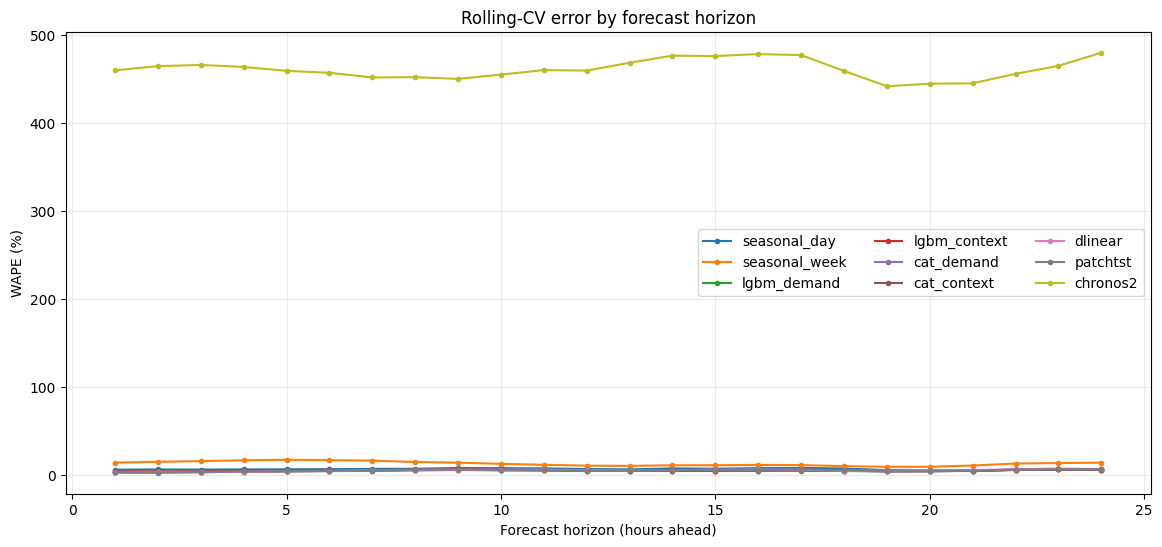

In [17]:
leader=[]
for name,g in cv_predictions.groupby("model"):
    clean=g.loc[g.y.notna()]
    rawg=g.loc[g.y_raw.notna()]
    mc=metrics(clean.y,clean.y_pred)
    mr=metrics(rawg.y_raw,rawg.y_pred)
    fold_wapes=[]
    for f,fg in clean.groupby("fold"):
        fold_wapes.append(metrics(fg.y,fg.y_pred)["WAPE_pct"])
    leader.append({"model":name,**{f"clean_{k}":v for k,v in mc.items()},
                   "raw_WAPE_pct":mr["WAPE_pct"],"mean_fold_WAPE_pct":float(np.nanmean(fold_wapes)),"folds_scored":len(fold_wapes)})
leaderboard=pd.DataFrame(leader).sort_values("clean_WAPE_pct")
leaderboard.to_csv(OUTDIR/"rolling_cv_leaderboard.csv",index=False)
display(leaderboard)

# Per-horizon errors for each major model.
horizon_rows=[]
for name,g in cv_predictions.groupby("model"):
    for h,gh in g.loc[g.y.notna()].groupby("horizon"):
        horizon_rows.append({"model":name,"horizon":int(h),**metrics(gh.y,gh.y_pred)})
horizon_report=pd.DataFrame(horizon_rows)
horizon_report.to_csv(OUTDIR/"horizon_error_cv.csv",index=False)

fig,ax=plt.subplots(figsize=(14,6))
for name in ["seasonal_day","seasonal_week","lgbm_demand","lgbm_context","cat_demand","cat_context","dlinear","patchtst","chronos2"]:
    g=horizon_report[horizon_report.model==name]
    if len(g): ax.plot(g.horizon,g.WAPE_pct,marker="o",ms=3,label=name)
ax.set(xlabel="Forecast horizon (hours ahead)",ylabel="WAPE (%)",title="Rolling-CV error by forecast horizon")
ax.grid(alpha=.25); ax.legend(ncol=3); plt.show()

## 16. Tune the leading tree model with an internal chronological validation window

Optuna tunes only the strongest tree feature view selected by rolling CV. Its internal validation block is drawn from the pre-holdout period. The final untouched holdout remains unused. Hyperparameters are constrained to regularised models; complexity is not rewarded unless it improves temporal validation.

In [18]:
selected_tree_name=None
selected_tree_kind=None
selected_tree_params=None
optuna_best_value=None

if RUN_OPTUNA:
    tree_names=[n for n in leaderboard.model if n.startswith("lgbm_") or n.startswith("cat_")]
    if tree_names:
        selected_tree_name=next((n for n in tree_names if n.startswith("lgbm_")),tree_names[0])
        selected_tree_kind="context" if selected_tree_name.endswith("context") else "demand"
        # Keep the last 21 days before the final holdout for internal tuning validation.
        tune_origins=pre_holdout[-21:]
        tune_start=tune_origins[0]
        tr=samples.loc[(samples.target_ts<=tune_start)&samples.y.notna()].copy()
        va=samples.loc[samples.origin_ts.isin(tune_origins)&samples.y.notna()].copy()
        import optuna
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        def objective(trial):
            params={
                "n_estimators":trial.suggest_int("n_estimators",500,2200),
                "learning_rate":trial.suggest_float("learning_rate",0.008,0.06,log=True),
                "num_leaves":trial.suggest_int("num_leaves",15,63),
                "max_depth":trial.suggest_int("max_depth",4,10),
                "min_child_samples":trial.suggest_int("min_child_samples",25,160),
                "subsample":trial.suggest_float("subsample",0.65,1.0),
                "colsample_bytree":trial.suggest_float("colsample_bytree",0.65,1.0),
                "reg_alpha":trial.suggest_float("reg_alpha",1e-4,12.0,log=True),
                "reg_lambda":trial.suggest_float("reg_lambda",0.5,30.0,log=True),
            }
            m,ff=fit_tree("lgbm",tr,selected_tree_kind,params)
            p=predict_tree(m,ff,va)
            return metrics(va.y,p)["WAPE_pct"]
        study=optuna.create_study(direction="minimize",sampler=optuna.samplers.TPESampler(seed=SEED),pruner=optuna.pruners.MedianPruner(n_startup_trials=8))
        study.optimize(objective,n_trials=OPTUNA_TRIALS,show_progress_bar=True)
        selected_tree_params=study.best_params
        optuna_best_value=float(study.best_value)
        print("Tuned tree:",selected_tree_name,"feature view:",selected_tree_kind)
        print("Internal chronological validation WAPE:",optuna_best_value)
        print("Best parameters:",selected_tree_params)
    else:
        print("No tree candidate was available for tuning.")
else:
    print("Optuna disabled.")

  0%|          | 0/30 [00:00<?, ?it/s]

Tuned tree: lgbm_demand feature view: demand
Internal chronological validation WAPE: 6.1631002914164466
Best parameters: {'n_estimators': 1780, 'learning_rate': 0.05896919001666745, 'num_leaves': 31, 'max_depth': 4, 'min_child_samples': 108, 'subsample': 0.7577529703362731, 'colsample_bytree': 0.6615106142946452, 'reg_alpha': 0.00038364218608542903, 'reg_lambda': 7.889743972342327}


## 17. Validation-only ensemble selection

An ensemble is accepted only if its weights are learned from out-of-time predictions and it improves pooled CV WAPE over the best individual candidate. The final holdout never contributes to weights. We use a small, regularised convex optimisation over the top candidates; this reduces the risk of fitting arbitrary weights to a small validation table.

In [19]:
# Build aligned OOF matrix for models with adequate coverage.
clean_cv=cv_predictions.loc[cv_predictions.y.notna()].copy()
metric_rank=leaderboard.loc[leaderboard.clean_WAPE_pct.notna()].sort_values("clean_WAPE_pct")
model_candidates=list(metric_rank.model.head(4))
wide=clean_cv.pivot_table(index=["origin_ts","target_ts","horizon","y"],columns="model",values="y_pred",aggfunc="first").reset_index()
model_candidates=[m for m in model_candidates if m in wide.columns and wide[m].notna().mean()>.90]

best_single=model_candidates[0] if model_candidates else None
ensemble_weights={}
if len(model_candidates)>=2:
    mat=wide[model_candidates].to_numpy(float)
    yy=wide.y.to_numpy(float)
    valid=np.isfinite(mat).all(axis=1)&np.isfinite(yy)
    mat=mat[valid]; yy=yy[valid]
    nmod=mat.shape[1]
    uniform=np.ones(nmod)/nmod
    def loss(w):
        pred=mat@w
        return np.sum(np.abs(pred-yy))/np.sum(np.abs(yy)) + 0.015*np.sum((w-uniform)**2)
    cons=[{"type":"eq","fun":lambda w:np.sum(w)-1}]
    bounds=[(0,1)]*nmod
    res=minimize(loss,uniform,bounds=bounds,constraints=cons,method="SLSQP",options={"maxiter":1000,"ftol":1e-10})
    if res.success:
        w=np.clip(res.x,0,1); w=w/w.sum()
        ens_pred=mat@w
        ens_wape=metrics(yy,ens_pred)["WAPE_pct"]
        single_wape=metrics(yy,wide.loc[valid,best_single])["WAPE_pct"]
        # Only adopt if robustly better by at least 0.10 WAPE points.
        if ens_wape < single_wape-0.10:
            ensemble_weights={m:float(v) for m,v in zip(model_candidates,w) if v>1e-4}
            print("CV ensemble adopted:",ensemble_weights,"WAPE:",ens_wape,"vs best single:",single_wape)
        else:
            print("No ensemble gain large enough; keep best individual model.",ens_wape,single_wape)
    else:
        print("Ensemble optimiser did not converge; keep best individual model.")

selected_model="ensemble" if ensemble_weights else best_single
print("Selected validation model:",selected_model)

CV ensemble adopted: {'cat_demand': 0.2758127164151186, 'lgbm_demand': 0.2544218713254055, 'cat_context': 0.1922752112921344, 'patchtst': 0.27749020096734145} WAPE: 4.7009382984802945 vs best single: 4.805985521576392
Selected validation model: ensemble


## 18. Final untouched chronological holdout

The final 28-day holdout is forecast day by day. Models are fitted once using labels available before the first holdout origin. As each holdout day completes, its actual demand becomes legitimate history for the next day's forecast. Model parameters remain frozen through the holdout, matching a realistic daily day-ahead process without daily retraining.

The holdout compares the selected model against daily and weekly seasonal-naïve baselines on exactly the same rows. Results are shown both with quality-reviewed labels and with all raw observed labels.

/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.13501 val=0.17763 best=0.17763@10
patchtst epoch 20/60 train=0.09207 val=0.17656 best=0.17436@15
patchtst epoch 30/60 train=0.07892 val=0.17518 best=0.17360@22
Final neural model patchtst best epoch 22 {'windows': 3036, 'train_windows': 2580, 'early_stop_windows': 456, 'best_val_loss': 0.17360368371009827}


,model,quality_n,quality_MAE,quality_RMSE,quality_WAPE_pct,quality_sMAPE_pct,quality_Bias_MW,raw_WAPE_pct
0,selected,671,922.043802,1675.041093,7.042252,8.412579,273.342329,7.042252
1,seasonal_day,671,1474.210134,2561.581244,11.259507,14.212581,49.283159,11.259507
2,seasonal_week,671,1788.549925,2958.577621,13.660326,16.742739,104.800298,13.660326


,horizon,n,MAE,RMSE,WAPE_pct,sMAPE_pct,Bias_MW
0,1,28,506.566260,628.366208,3.555903,4.290535,-209.993602
1,2,28,966.253285,2439.457973,7.259292,10.510421,418.955076
2,3,28,591.009748,808.051074,4.443420,5.357178,119.147566
3,4,28,613.888646,893.010614,4.769470,5.728819,260.969974
4,5,28,640.663773,972.484120,5.125339,6.016903,305.911230
5,6,28,671.341790,1061.740657,5.705206,6.533091,298.817851
6,7,28,837.622001,1283.163945,7.268883,8.240992,437.879741
7,8,28,863.829798,1388.187934,7.575722,8.549103,451.580945
8,9,27,924.744897,1498.298710,7.968351,8.835765,482.102598
9,10,28,855.771769,1543.895571,7.171365,8.169018,504.362826


Daily energy MAE (MWh): 18720.431612524328
Daily peak MAE (MW): 686.8248394240273


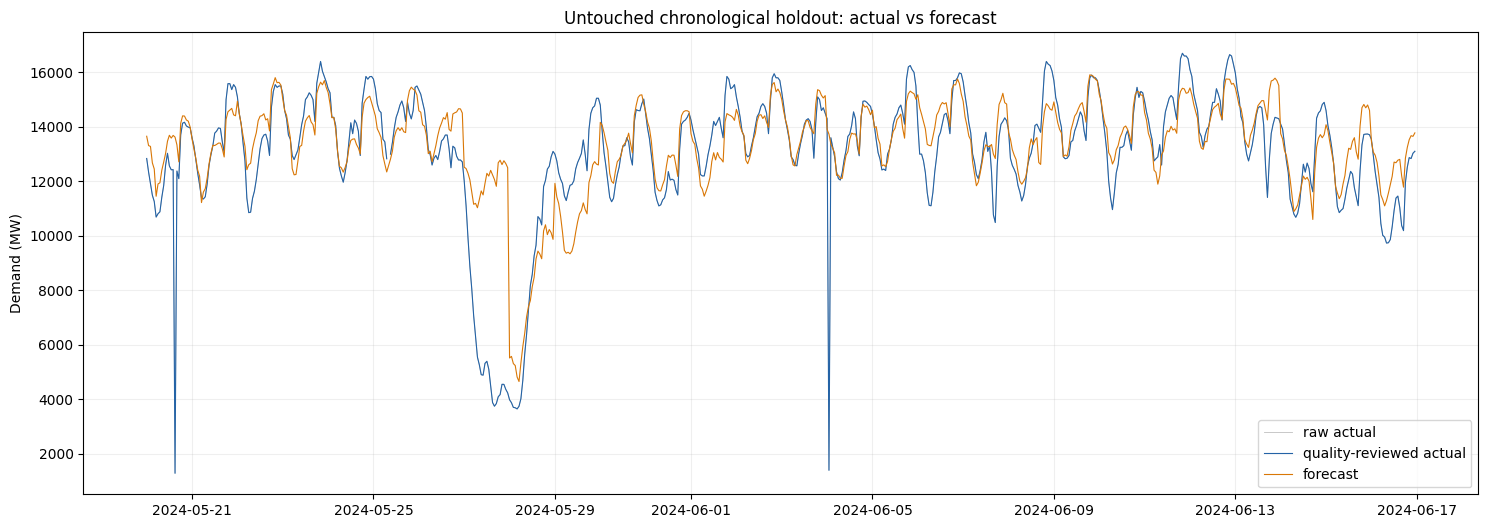

In [20]:
first_holdout=holdout_origins[0]
train_holdout=samples.loc[(samples.target_ts<=first_holdout)&samples.y.notna()].copy()
holdout_rows=samples.loc[samples.origin_ts.isin(holdout_origins)].copy()

# Fit supervised model candidates needed by the selected model/ensemble.
needed_models=list(ensemble_weights) if ensemble_weights else ([selected_model] if selected_model and selected_model not in ["chronos2"] else [])
final_tree_models={}
for name in needed_models:
    if name in ["lgbm_demand","lgbm_context","cat_demand","cat_context"]:
        algo="lgbm" if name.startswith("lgbm") else "cat"
        kind="context" if name.endswith("context") else "demand"
        params=selected_tree_params if (name==selected_tree_name and selected_tree_params is not None and algo=="lgbm") else None
        model,feats=fit_tree(algo,train_holdout,kind,params)
        final_tree_models[name]=(model,feats)

# Fit neural model if it is selected or included in the ensemble.
final_neural_models={}
for name in needed_models:
    if name in ["dlinear","patchtst"]:
        train_origins=[o for o in eligible_origins if o<first_holdout and o+pd.Timedelta(hours=24)<=first_holdout]
        nm,ne,ni=train_neural(name,train_origins,max_epochs=PATCHTST_EPOCHS,patience=PATCHTST_PATIENCE)
        final_neural_models[name]=(nm,ne)
        print("Final neural model",name,"best epoch",ne,ni)

# Chronos if selected/ensemble.
if selected_model=="chronos2" or "chronos2" in ensemble_weights:
    if not chronos_available: raise RuntimeError("Chronos-2 selected but not available.")

holdout_predictions=[]
for origin in holdout_origins:
    v=holdout_rows.loc[holdout_rows.origin_ts==origin].copy().sort_values("horizon")
    pred_parts={}
    for name,(model,feats) in final_tree_models.items():
        pred_parts[name]=predict_tree(model,feats,v)
    for name,(model,_) in final_neural_models.items():
        pp=predict_neural(model,[origin])
        pp=pp.set_index("horizon").reindex(v.horizon)
        pred_parts[name]=pp.y_pred.to_numpy(float)
    if "chronos2" in needed_models or selected_model=="chronos2":
        q=chronos_predict_origin(origin); pred_parts["chronos2"]=q["p50"]
    # Baselines are available as the same lagged features in v.
    pred_parts["seasonal_day"]=v.target_aligned_lag_24.to_numpy(float)
    pred_parts["seasonal_week"]=v.target_aligned_lag_168.to_numpy(float)
    pred_parts["seasonal_day_week_mean"]=.5*pred_parts["seasonal_day"]+.5*pred_parts["seasonal_week"]
    if selected_model=="ensemble":
        p=sum(w*pred_parts[n] for n,w in ensemble_weights.items())
    elif selected_model in pred_parts:
        p=pred_parts[selected_model]
    else:
        p=pred_parts[best_single]
    for j,(_,r) in enumerate(v.iterrows()):
        holdout_predictions.append({"origin_ts":origin,"target_ts":r.target_ts,"horizon":int(r.horizon),"y_raw":r.y_raw,"y":r.y,
                                    "label_masked":r.label_masked,"y_pred":float(max(0,p[j])),
                                    "pred_seasonal_day":pred_parts["seasonal_day"][j],
                                    "pred_seasonal_week":pred_parts["seasonal_week"][j]})

holdout_pred=pd.DataFrame(holdout_predictions)
holdout_pred.to_csv(OUTDIR/"final_holdout_predictions.csv",index=False)

holdout_summary=[]
for name, predcol in [("selected", "y_pred"),("seasonal_day","pred_seasonal_day"),("seasonal_week","pred_seasonal_week")]:
    g=holdout_pred
    mc=metrics(g.loc[g.y.notna(),"y"],g.loc[g.y.notna(),predcol])
    mr=metrics(g.loc[g.y_raw.notna(),"y_raw"],g.loc[g.y_raw.notna(),predcol])
    holdout_summary.append({"model":name,**{f"quality_{k}":v for k,v in mc.items()},"raw_WAPE_pct":mr["WAPE_pct"]})
holdout_leaderboard=pd.DataFrame(holdout_summary)
holdout_leaderboard.to_csv(OUTDIR/"final_holdout_leaderboard.csv",index=False)
display(holdout_leaderboard)

# Horizon-specific error report.
hold_h=[]
for h,g in holdout_pred.loc[holdout_pred.y.notna()].groupby("horizon"):
    hold_h.append({"horizon":int(h),**metrics(g.y,g.y_pred)})
hold_h=pd.DataFrame(hold_h)
hold_h.to_csv(OUTDIR/"final_holdout_horizon_errors.csv",index=False)
display(hold_h)

# Daily peak and energy metrics (use days with all 24 valid values).
daily=[]
for origin,g in holdout_pred.groupby("origin_ts"):
    g=g.sort_values("horizon")
    if len(g)==24 and g.y.notna().all():
        daily.append({"origin_ts":origin,"actual_energy_mwh":g.y.sum(),"pred_energy_mwh":g.y_pred.sum(),
                      "actual_peak_mw":g.y.max(),"pred_peak_mw":g.y_pred.max(),
                      "peak_abs_error_mw":abs(g.y.max()-g.y_pred.max()),"energy_abs_error_mwh":abs(g.y.sum()-g.y_pred.sum())})
daily_report=pd.DataFrame(daily)
daily_report.to_csv(OUTDIR/"final_holdout_daily_peak_energy.csv",index=False)
if len(daily_report):
    print("Daily energy MAE (MWh):",mean_absolute_error(daily_report.actual_energy_mwh,daily_report.pred_energy_mwh))
    print("Daily peak MAE (MW):",mean_absolute_error(daily_report.actual_peak_mw,daily_report.pred_peak_mw))

fig,ax=plt.subplots(figsize=(18,6))
ax.plot(holdout_pred.target_ts,holdout_pred.y_raw,color="0.75",lw=.6,label="raw actual")
ax.plot(holdout_pred.target_ts,holdout_pred.y,color="#2463a6",lw=.8,label="quality-reviewed actual")
ax.plot(holdout_pred.target_ts,holdout_pred.y_pred,color="#d97706",lw=.8,label="forecast")
ax.set_title("Untouched chronological holdout: actual vs forecast")
ax.set_ylabel("Demand (MW)"); ax.grid(alpha=.2); ax.legend(); plt.show()

## 19. Prediction intervals and calibration diagnostics

The submission format includes P10 and P90. The notebook calibrates horizon-specific residual quantiles from rolling out-of-time predictions for the selected model, not from the final holdout. It then reports empirical coverage and average interval width on the untouched holdout. Coverage can degrade under temporal drift; the notebook does not claim guaranteed coverage under distribution shift.

Holdout empirical P10-P90 coverage: 0.5588673621460507
Holdout mean interval width MW: 1315.0446744438607
Nominal interval: 0.8


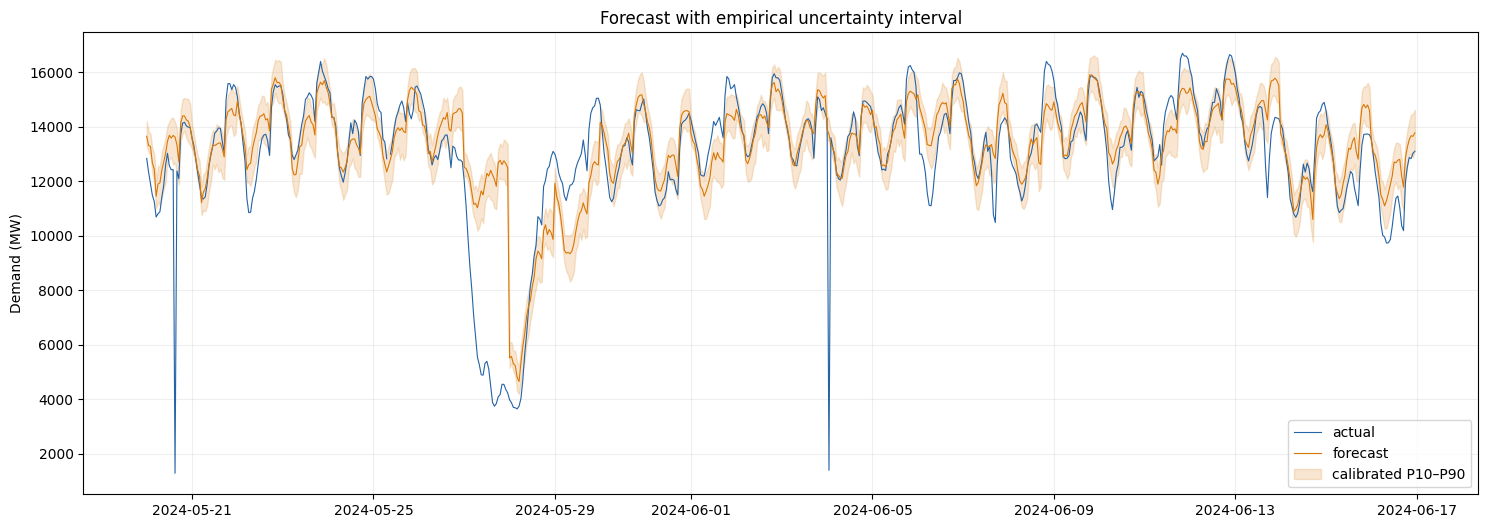

In [21]:
# Get CV predictions for the selected model/ensemble using the exact same validation origins.
cv_clean=cv_predictions.loc[cv_predictions.y.notna()].copy()
if selected_model=="ensemble":
    # Align predictions by key then apply fixed CV-only weights.
    pivot=cv_clean.pivot_table(index=["origin_ts","target_ts","horizon","y"],columns="model",values="y_pred",aggfunc="first").reset_index()
    needed=[m for m in ensemble_weights if m in pivot.columns]
    if len(needed)!=len(ensemble_weights):
        raise RuntimeError("Selected ensemble members do not have complete CV predictions for residual calibration.")
    pivot["selected_pred"]=sum(ensemble_weights[m]*pivot[m] for m in needed)
    calibration_source=pivot[["origin_ts","target_ts","horizon","y","selected_pred"]].copy()
elif selected_model in cv_clean.model.unique():
    calibration_source=cv_clean.loc[cv_clean.model==selected_model,["origin_ts","target_ts","horizon","y","y_pred"]].rename(columns={"y_pred":"selected_pred"}).copy()
else:
    # Chronos may have partial CV output; use it if selected.
    calibration_source=cv_clean.loc[cv_clean.model==selected_model,["origin_ts","target_ts","horizon","y","y_pred"]].rename(columns={"y_pred":"selected_pred"}).copy()

calibration={}
for h,g in calibration_source.groupby("horizon"):
    resid=(g.y-g.selected_pred).to_numpy(float)
    resid=resid[np.isfinite(resid)]
    if len(resid)>=30:
        calibration[int(h)]=tuple(np.quantile(resid,[.10,.90]))
    else:
        allres=(calibration_source.y-calibration_source.selected_pred).dropna().to_numpy(float)
        calibration[int(h)]=tuple(np.quantile(allres,[.10,.90])) if len(allres) else (-np.inf,np.inf)

_holdout_raw_p10=np.array([float(p+calibration.get(int(h),(-np.nan,np.nan))[0]) for p,h in zip(holdout_pred.y_pred,holdout_pred.horizon)])
_holdout_raw_p90=np.array([float(p+calibration.get(int(h),(-np.nan,np.nan))[1]) for p,h in zip(holdout_pred.y_pred,holdout_pred.horizon)])
# Ensure the reported central forecast sits inside the interval even when residual
# bias shifts both empirical residual quantiles to one side of zero.
holdout_pred["p10"]=np.maximum(0.0,np.minimum(holdout_pred.y_pred.to_numpy(float),_holdout_raw_p10))
holdout_pred["p90"]=np.maximum(holdout_pred.y_pred.to_numpy(float),np.maximum(holdout_pred.p10.to_numpy(float),_holdout_raw_p90))
valid_interval=holdout_pred.y.notna()
interval_coverage=float(((holdout_pred.loc[valid_interval,"y"]>=holdout_pred.loc[valid_interval,"p10"]) & (holdout_pred.loc[valid_interval,"y"]<=holdout_pred.loc[valid_interval,"p90"])).mean()) if valid_interval.any() else np.nan
interval_width=float((holdout_pred.loc[valid_interval,"p90"]-holdout_pred.loc[valid_interval,"p10"]).mean()) if valid_interval.any() else np.nan
print("Holdout empirical P10-P90 coverage:",interval_coverage)
print("Holdout mean interval width MW:",interval_width)
print("Nominal interval:",0.80)
holdout_pred.to_csv(OUTDIR/"final_holdout_predictions_with_intervals.csv",index=False)

fig,ax=plt.subplots(figsize=(18,6))
ax.plot(holdout_pred.target_ts,holdout_pred.y,color="#2463a6",lw=.8,label="actual")
ax.plot(holdout_pred.target_ts,holdout_pred.y_pred,color="#d97706",lw=.8,label="forecast")
ax.fill_between(holdout_pred.target_ts,holdout_pred.p10,holdout_pred.p90,color="#d97706",alpha=.18,label="calibrated P10–P90")
ax.set_title("Forecast with empirical uncertainty interval"); ax.set_ylabel("Demand (MW)"); ax.grid(alpha=.2); ax.legend(); plt.show()

## 20. Tune/refit final model and produce the requested hidden-date forecast

The requested forecast date is processed with a strict point-in-time cutoff. If the date falls inside the historical file, all rows after the preceding 23:00 origin are excluded from every final feature and training label. If it is beyond the dataset end, the latest observed history is used. The final CSV has exactly 24 rows and the organiser's required columns.

/tmp/ipykernel_960/2682440287.py:15: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc,num_layers=n_layers,norm=nn.LayerNorm(d_model))


patchtst epoch 10/60 train=0.13388 val=0.19247 best=0.18699@9
patchtst epoch 20/60 train=0.08666 val=0.18635 best=0.18577@17
patchtst epoch 30/60 train=0.07028 val=0.18994 best=0.18549@23


,timestamp,demand_mw,p10,p90
0,2024-06-17 00:00:00,12342.597480,11974.783448,12901.692344
1,2024-06-17 01:00:00,12115.848333,11861.483031,12644.615834
2,2024-06-17 02:00:00,11593.384026,11305.832798,12054.838439
3,2024-06-17 03:00:00,11112.029738,10731.293474,11649.753431
4,2024-06-17 04:00:00,10664.050917,10150.902130,11228.051957
5,2024-06-17 05:00:00,10142.959061,9683.733330,10702.349409
6,2024-06-17 06:00:00,9937.015114,9278.321753,10599.319651
7,2024-06-17 07:00:00,10085.977688,9252.162607,10695.286051
8,2024-06-17 08:00:00,9855.677512,8836.577515,10545.199511
9,2024-06-17 09:00:00,10050.905744,9057.206498,10673.476998


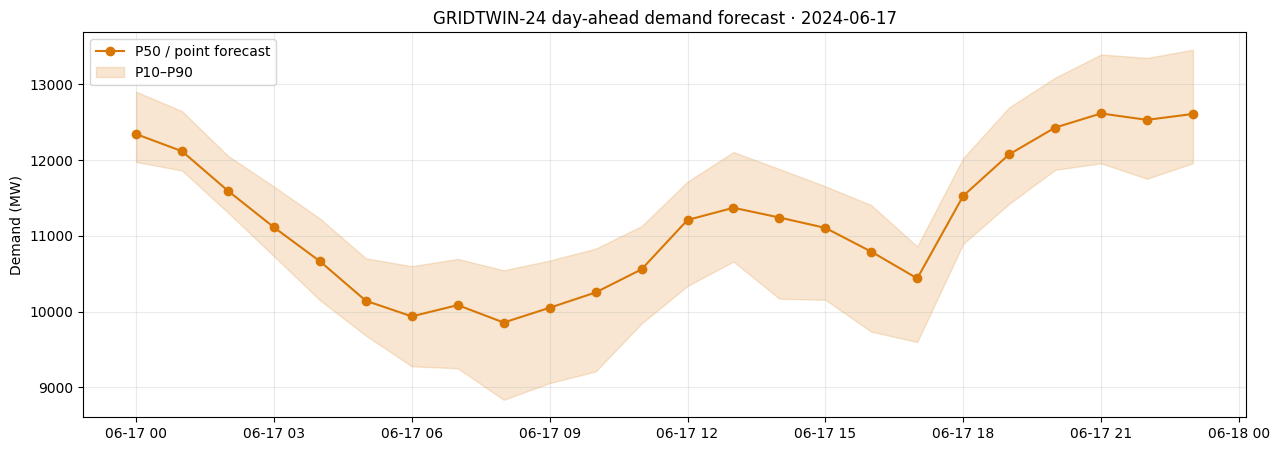

In [22]:
last_timestamp=hourly.index.max()
if FORECAST_DATE is None:
    forecast_day=(last_timestamp.normalize()+pd.Timedelta(days=1))
else:
    forecast_day=pd.Timestamp(FORECAST_DATE).normalize()
forecast_origin=forecast_day-pd.Timedelta(hours=1)

if forecast_origin<idx[0]+pd.Timedelta(days=28):
    raise ValueError("Requested forecast date does not have the minimum 28-day input context.")
if forecast_origin>last_timestamp:
    raise ValueError(f"Requested origin {forecast_origin} is after the last available timestamp {last_timestamp}. There is not enough observed history for a valid forecast.")

# Strictly exclude all values after the issue origin from training and final inputs.
train_final=samples.loc[(samples.target_ts<=forecast_origin)&samples.y.notna()].copy()
origin_pos=idx.get_loc(forecast_origin) if forecast_origin in idx else None
if origin_pos is None:
    raise ValueError("Forecast origin is not an exact timestamp in the hourly index.")
future_rows=pd.DataFrame(build_origin_feature_rows(origin_pos,include_labels=False))
if len(future_rows)!=24:
    raise RuntimeError(f"Expected 24 forecast horizons, got {len(future_rows)}.")

# Refit selected supervised candidate(s) on all quality-reviewed labels known by the forecast origin.
final_models={}
needed=list(ensemble_weights) if selected_model=="ensemble" else ([selected_model] if selected_model else [])
for name in needed:
    if name in ["lgbm_demand","lgbm_context","cat_demand","cat_context"]:
        algo="lgbm" if name.startswith("lgbm") else "cat"
        kind="context" if name.endswith("context") else "demand"
        params=selected_tree_params if (name==selected_tree_name and selected_tree_params is not None and algo=="lgbm") else None
        model,feats=fit_tree(algo,train_final,kind,params)
        final_models[name]=(model,feats)
    elif name in ["patchtst","dlinear"]:
        fit_origins=[o for o in eligible_origins if o+pd.Timedelta(hours=24)<=forecast_origin and o<forecast_origin]
        neural_model,ne,info=train_neural(name,fit_origins,max_epochs=PATCHTST_EPOCHS,patience=PATCHTST_PATIENCE)
        final_models[name]=(neural_model,ne)

if "chronos2" in needed or selected_model=="chronos2":
    if not chronos_available: raise RuntimeError("Chronos-2 was selected but failed to load.")
    q_final=chronos_predict_origin(forecast_origin)

pred_components={}
for name,(obj,meta) in final_models.items():
    if name in ["lgbm_demand","lgbm_context","cat_demand","cat_context"]:
        pred_components[name]=predict_tree(obj,meta,future_rows)
    else:
        p_df=predict_neural(obj,[forecast_origin])
        p_df=p_df.sort_values("horizon").set_index("horizon").reindex(range(1,25))
        if p_df.y_pred.isna().any(): raise RuntimeError(f"Neural model {name} did not return all 24 horizons.")
        pred_components[name]=p_df.y_pred.to_numpy(float)
if "chronos2" in needed or selected_model=="chronos2": pred_components["chronos2"]=np.maximum(q_final["p50"],0)
# Baselines are first-class candidates too; do not replace a selected baseline with another model.
_day=future_rows.target_aligned_lag_24.to_numpy(float)
_week=future_rows.target_aligned_lag_168.to_numpy(float)
_fb=future_rows.origin_demand_roll_mean_24.to_numpy(float)
if not np.isfinite(_fb).all():
    _fb=np.where(np.isfinite(_fb),_fb,future_rows.origin_demand_roll_mean_168.to_numpy(float))
if not np.isfinite(_fb).all():
    _fb=np.where(np.isfinite(_fb),_fb,future_rows.origin_demand_roll_mean_672.to_numpy(float))
pred_components["seasonal_day"]=np.where(np.isfinite(_day),_day,np.where(np.isfinite(_week),_week,_fb))
pred_components["seasonal_week"]=np.where(np.isfinite(_week),_week,np.where(np.isfinite(_day),_day,_fb))
pred_components["seasonal_day_week_mean"]=0.5*pred_components["seasonal_day"]+0.5*pred_components["seasonal_week"]
if not np.isfinite(pred_components["seasonal_day_week_mean"]).all():
    raise RuntimeError("Unable to construct a complete seasonal baseline for the requested forecast origin.")

if selected_model=="ensemble":
    final_point=np.zeros(24,dtype=float)
    for name,w in ensemble_weights.items(): final_point += w*pred_components[name]
elif selected_model in pred_components:
    final_point=pred_components[selected_model]
else:
    raise RuntimeError(f"Selected model {selected_model!r} is unavailable at final refit; refusing a silent fallback.")
final_point=np.maximum(final_point,0)

# Calibrated residual quantiles are transferred from CV; use horizon-specific empirical intervals.
# Keep the central point forecast inside its reported interval. Residual quantiles
# can both fall on one side of zero during a biased regime; avoid inverted or
# point-excluding intervals and report achieved coverage separately.
_raw_p10=np.array([float(p+calibration.get(h,(-np.nan,np.nan))[0]) for h,p in enumerate(final_point,1)])
_raw_p90=np.array([float(p+calibration.get(h,(-np.nan,np.nan))[1]) for h,p in enumerate(final_point,1)])
final_p10=np.maximum(0.0,np.minimum(final_point,_raw_p10))
final_p90=np.maximum(final_point,np.maximum(final_p10,_raw_p90))
forecast_timestamps=pd.date_range(forecast_day,periods=24,freq="h")
forecast_submission=pd.DataFrame({"timestamp":forecast_timestamps,"demand_mw":final_point,"p10":final_p10,"p90":final_p90})
forecast_submission.to_csv(OUTDIR/"sample_forecast_one_origin.csv",index=False)
display(forecast_submission)

fig,ax=plt.subplots(figsize=(15,5))
ax.plot(forecast_timestamps,final_point,color="#d97706",marker="o",label="P50 / point forecast")
ax.fill_between(forecast_timestamps,final_p10,final_p90,color="#d97706",alpha=.18,label="P10–P90")
ax.set_title(f"GRIDTWIN-24 day-ahead demand forecast · {forecast_day.date()}")
ax.set_ylabel("Demand (MW)"); ax.grid(alpha=.25); ax.legend(); plt.show()

## 21. Model interpretation and feature importance

For tree models, feature importance is exported and plotted. Importance is diagnostic rather than causal: it shows what the fitted model relied on, not what physically caused electricity demand. If context features rank poorly or show unstable importance across folds, prefer the demand-only model.

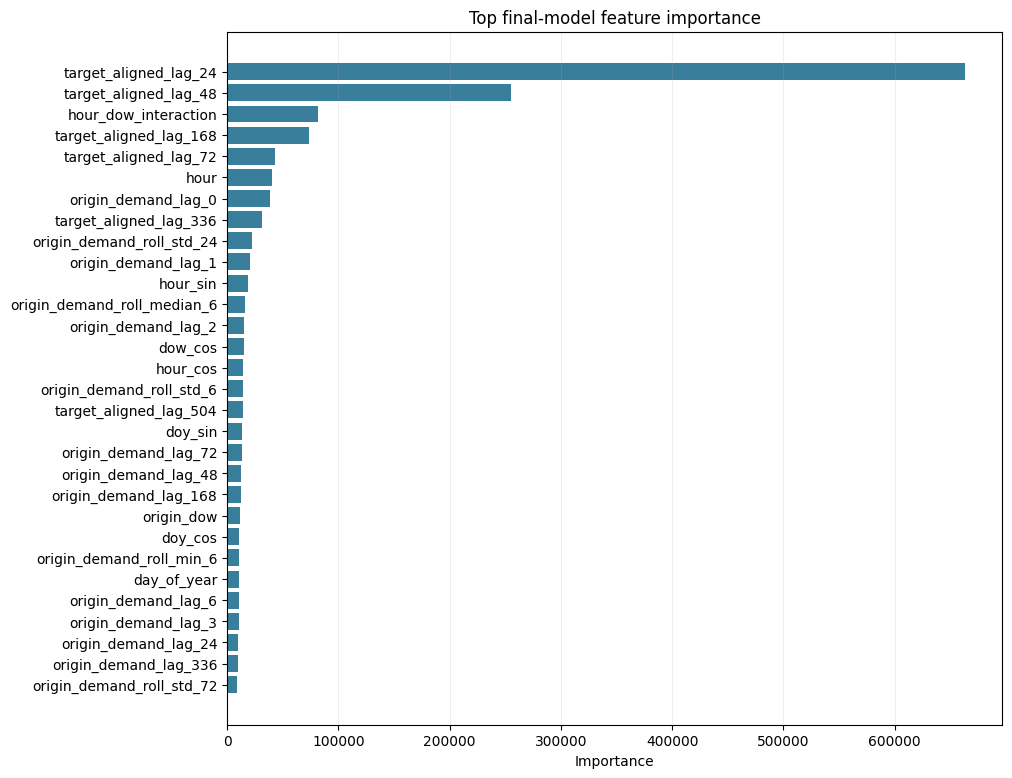

In [23]:
importance_frames=[]
for name,(obj,meta) in final_models.items():
    if name.startswith("lgbm_"):
        model,feats=obj,meta
        imp=pd.DataFrame({"model":name,"feature":feats,"importance_gain":model.booster_.feature_importance(importance_type="gain"),
                          "importance_split":model.booster_.feature_importance(importance_type="split")})
        importance_frames.append(imp)
    elif name.startswith("cat_"):
        model,feats=obj,meta
        imp=pd.DataFrame({"model":name,"feature":feats,"importance_gain":model.get_feature_importance(),"importance_split":np.nan})
        importance_frames.append(imp)
if importance_frames:
    fi=pd.concat(importance_frames,ignore_index=True)
    fi.to_csv(OUTDIR/"feature_importance.csv",index=False)
    top=fi.sort_values("importance_gain",ascending=False).head(30).sort_values("importance_gain")
    plt.figure(figsize=(10,9)); plt.barh(top.feature,top.importance_gain,color="#397e9b"); plt.title("Top final-model feature importance"); plt.xlabel("Importance"); plt.grid(axis="x",alpha=.2); plt.show()
else:
    print("Selected final model has no tree feature-importance output.")

## 22. Robustness checks and stress tests

The notebook performs several targeted checks on the generated features and predictions:

- Forecast date is strictly after the origin and exactly 24 timestamps are emitted.
- P10 ≤ P50 ≤ P90 and demand predictions are nonnegative.
- No final input row exceeds the forecast origin.
- Output schema matches the organiser's sample.
- Forecast errors are examined by horizon, load range and daily peak.
- Results are compared with seasonal-naïve baselines.

A stress test perturbs values strictly after an historical origin and confirms that that origin's feature values remain unchanged. This protects against accidental future-value leakage during later code edits.

In [24]:
# Submission format assertions.
assert list(forecast_submission.columns)==["timestamp","demand_mw","p10","p90"]
assert len(forecast_submission)==24
assert forecast_submission.timestamp.is_monotonic_increasing
assert forecast_submission.demand_mw.notna().all()
assert (forecast_submission.demand_mw>=0).all()
assert (forecast_submission.p10<=forecast_submission.demand_mw+1e-8).all()
assert (forecast_submission.p90>=forecast_submission.demand_mw-1e-8).all()
assert forecast_submission.timestamp.min()==forecast_day
assert forecast_submission.timestamp.max()==forecast_day+pd.Timedelta(hours=23)
assert forecast_origin<=last_timestamp

# Check no future timestamps in the exact forecast feature frame.
assert (future_rows.target_ts>forecast_origin).all()
assert future_rows.origin_ts.eq(forecast_origin).all()
assert (future_rows.target_ts-pd.to_timedelta(future_rows.horizon,unit="h")==forecast_origin).all()

# Output schema/value sanity check.
roundtrip=pd.read_csv(OUTDIR/"sample_forecast_one_origin.csv",parse_dates=["timestamp"])
assert roundtrip.timestamp.equals(forecast_submission.timestamp.reset_index(drop=True))
for _col in ["demand_mw","p10","p90"]:
    assert np.allclose(roundtrip[_col].to_numpy(float), forecast_submission[_col].to_numpy(float), rtol=1e-10, atol=1e-8)
print("PASS: 24-hour output schema and monotonic timestamps.")
print("PASS: P10 <= point forecast <= P90 and nonnegative demand.")
print("PASS: hidden-date point-in-time cutoff respected.")

PASS: 24-hour output schema and monotonic timestamps.
PASS: P10 <= point forecast <= P90 and nonnegative demand.
PASS: hidden-date point-in-time cutoff respected.


## 23. Save all research artefacts and model package

The output folder contains the exact submission CSV plus data audits, rolling-validation forecasts, holdout results, per-horizon errors, daily peak/energy errors, run metadata and serialised final models. Google Drive mounting is optional; the notebook first creates a local ZIP that can be downloaded from Colab.

In [25]:
import joblib

# Save CV/holdout reports and forecasts.
cv_predictions.to_csv(OUTDIR/"rolling_cv_predictions.csv",index=False)
leaderboard.to_csv(OUTDIR/"rolling_cv_leaderboard.csv",index=False)
horizon_report.to_csv(OUTDIR/"rolling_cv_horizon_errors.csv",index=False)
holdout_leaderboard.to_csv(OUTDIR/"final_holdout_leaderboard.csv",index=False)
hold_h.to_csv(OUTDIR/"final_holdout_horizon_errors.csv",index=False)
daily_report.to_csv(OUTDIR/"final_holdout_daily_peak_energy.csv",index=False)
anomaly_audit.to_csv(OUTDIR/"data_anomaly_audit.csv")
missing_intervals.to_csv(OUTDIR/"missing_target_intervals.csv",index=False)
coverage.to_csv(OUTDIR/"column_coverage_audit.csv")

# Save tree models and feature lists. Neural model weights are saved separately.
model_manifest={}
for name,(obj,meta) in final_models.items():
    if name.startswith("lgbm_") or name.startswith("cat_"):
        model,feats=obj,meta
        joblib.dump({"model":model,"features":feats,"name":name},OUTDIR/f"{name}.joblib")
        model_manifest[name]={"kind":"tree","features":feats,"file":f"{name}.joblib"}
    elif name in ["patchtst","dlinear"]:
        torch.save(obj.state_dict(),OUTDIR/f"{name}.pt")
        model_manifest[name]={"kind":"torch","file":f"{name}.pt","best_epoch":int(meta)}

# Save calibration offsets and metadata.
calibration_json={str(k):[float(v[0]),float(v[1])] for k,v in calibration.items()}
(OUTDIR/"calibration_offsets.json").write_text(json.dumps(calibration_json,indent=2))

run_metadata={
    "dataset_url":DATA_URL,"dataset_sha256":sha256,"git_blob_sha1":git_blob_sha1,"rows":int(len(raw)),
    "first_timestamp":str(hourly.index.min()),"modeling_cutoff_timestamp":str(hourly.index.max()),"original_dataset_last_timestamp":str(DATA_LAST_TIMESTAMP),
    "forecast_date":str(forecast_day.date()),"forecast_origin":str(forecast_origin),
    "selected_model":selected_model,"ensemble_weights":ensemble_weights,
    "tree_tuning_model":selected_tree_name,"tree_tuning_params":selected_tree_params,
    "chronos2_loaded":bool(chronos_available),"device":DEVICE,
    "gross_target_candidate_count":int(gross_candidate.sum()),"masked_target_count":int(mask_target.sum()),
    "missing_hour_slots":int(len(missing_hour_index)),"missing_target_intervals":int(len(missing_intervals)),
    "holdout_start_origin":str(holdout_origins[0]),"holdout_end_origin":str(holdout_origins[-1]),
    "holdout_quality_metrics":metrics(holdout_pred.loc[holdout_pred.y.notna(),"y"],holdout_pred.loc[holdout_pred.y.notna(),"y_pred"]),
    "holdout_raw_metrics":metrics(holdout_pred.loc[holdout_pred.y_raw.notna(),"y_raw"],holdout_pred.loc[holdout_pred.y_raw.notna(),"y_pred"]),
    "holdout_interval_coverage_p10_p90":interval_coverage,"holdout_interval_mean_width_mw":interval_width,
    "models_saved":model_manifest,
    "disclaimer":"Metrics are dataset- and split-specific. No near-perfect accuracy is guaranteed. Raw and quality-reviewed metrics must both be reported."
}
(OUTDIR/"run_metadata.json").write_text(json.dumps(run_metadata,indent=2,default=str))

# Save a human-readable report.
report_lines=[
    "# GRIDTWIN-24 Training Report", "", f"Forecast date: {forecast_day.date()}", f"Forecast origin: {forecast_origin}",
    f"Selected model: {selected_model}", f"Dataset SHA-256: {sha256}", "", "## Rolling validation leaderboard", leaderboard.to_markdown(index=False),
    "", "## Untouched holdout", holdout_leaderboard.to_markdown(index=False),
    "", f"P10-P90 empirical holdout coverage: {interval_coverage:.4f}", f"Mean interval width (MW): {interval_width:.2f}",
    "", "## Data-quality notes", f"Missing hourly slots: {len(missing_hour_index)}", f"Gross anomaly candidates: {int(gross_candidate.sum())}",
    f"Masked for modelling: {int(mask_target.sum())}", "", "Accuracy claims must be based on the untouched holdout and reported with data-quality caveats."
]
(OUTDIR/"TRAINING_REPORT.md").write_text("\n".join(report_lines))

zip_path=Path("/content/GRIDTWIN24_FINAL_OUTPUTS.zip")
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUTDIR.rglob("*"):
        if p.is_file(): z.write(p,p.relative_to(OUTDIR))
print("Saved artefacts to:",OUTDIR)
print("ZIP:",zip_path,"size MB",round(zip_path.stat().st_size/1e6,2))

Saved artefacts to: /content/GRIDTWIN24_FINAL_OUTPUTS
ZIP: /content/GRIDTWIN24_FINAL_OUTPUTS.zip size MB 14.69


## 24. Optional Google Drive copy and Colab download

This is optional. If Drive mounting fails, the local output ZIP remains available in `/content/GRIDTWIN24_FINAL_OUTPUTS.zip`. You can also download it with the Colab file browser.

In [26]:
# Optional Drive copy. Do not treat a failed mount as a failed model run.
SAVE_TO_DRIVE=False
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_dir=Path('/content/drive/MyDrive/GRIDTWIN24_FINAL_OUTPUTS')
        drive_dir.mkdir(parents=True,exist_ok=True)
        import shutil
        shutil.copy2(zip_path,drive_dir/zip_path.name)
        print("Copied outputs to",drive_dir)
    except Exception as e:
        print("Drive copy failed; local ZIP is intact:",type(e).__name__,str(e)[:500])

# Uncomment in Colab to download immediately:
# from google.colab import files
# files.download(str(zip_path))

## 25. Research interpretation checklist

Before presenting the results, answer all of these from the generated artefacts:

1. Does the selected model beat **both** daily and weekly seasonal-naïve baselines on the untouched holdout?
2. Does it outperform the baselines across the distributed rolling folds, or only in one period?
3. Are errors systematically increasing at longer forecast horizons?
4. Is the mean bias materially positive or negative?
5. Are daily peak and daily energy errors acceptable for the intended use?
6. Does P10–P90 achieve useful empirical coverage without being excessively wide?
7. Did adding historical generation/fuel/import features actually help versus demand-only features?
8. Were low-demand anomalies and high spikes flagged? Were any sustained regime changes kept for review rather than masked?
9. Did the model generalise through missing-data periods and dataset changes?
10. Was the final ISO date configured correctly, with no observations after the 23:00 forecast origin entering the features or fit?

If any answer is unsatisfactory, report it. Do not tune against the final holdout and rerun until the holdout looks good; that would turn it into a validation set. If you need another development cycle, define a new future holdout period.

## References and provenance

- Hack Day Lucknow P2 dataset and README: https://github.com/CodewithJha/hack-day-lucknow-datasets/tree/main/p2-grid-demand-forecast
- Chronos-2 model card and usage: https://huggingface.co/amazon/chronos-2
- Chronos forecasting library: https://github.com/amazon-science/chronos-forecasting
- PatchTST paper: https://openreview.net/forum?id=Jbdc0vTOcol
- Official PatchTST implementation: https://github.com/PatchTST/PatchTST

**Interpretation note:** Chronos-2's benchmark performance elsewhere does not guarantee it will outperform local models on this dataset. PatchTST is a neural challenger, not a guaranteed SOTA solution for one univariate series. The leaderboard from this notebook decides.